# I. Mục tiêu khám phá dữ liệu
Trả lời các câu hỏi phục vụ cho các bước sau:
1. Dữ liệu có đủ liên tục và đáng tin cậy để làm chuỗi thời gian không?
2. PM2.5 có phân phối và mức biến động như thế nào?
3. Có quy luật theo giờ, ngày, tháng, mùa hay không?
4. PM2.5 phụ thuộc vào lịch sử của chính nó trong bao lâu?
5. Forecast horizon càng xa thì bài toán khó lên như thế nào?
6. Các chất ô nhiễm khác có chứa thông tin cho PM2.5 tương lai không?
7. Yếu tố khí tượng có quan hệ tuyến tính hay phi tuyến với PM2.5?
8. Quan hệ khí tượng - PM2.5 có thay đổi theo mùa không?
9. Hướng gió, mưa và tổ hợp các điều kiện khí tượng có liên hệ gì với PM2.5?
10. Các đợt PM2.5 cao có phải chỉ là spike lẻ hay kéo dài thành episode?
11. Phân phối dữ liệu có thay đổi giữa các năm không?




# II. Import Data

In [7]:
import os
import sys
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
PROC = ROOT / 'data' / 'processed'


sys.path.insert(0, str(ROOT / 'src'))


pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', lambda x: f'{x:.3f}')

In [8]:
df = pd.read_csv(PROC / 'merged_data.csv')
print(f'Kích thước dữ liệu gốc: {df.shape[0]} dòng, {df.shape[1]} cột')


df = df.drop(columns=[c for c in ['AQI'] if c in df.columns])
df_raw = df.copy()

print(f'Sau khi bỏ AQI: {df.shape[0]} dòng, {df.shape[1]} cột')
display(df.head())

Kích thước dữ liệu gốc: 40608 dòng, 24 cột
Sau khi bỏ AQI: 40608 dòng, 23 cột


,Local Time,CO,NO2,O3,PM10,PM25,SO2,Temperature,Relative Humidity,Precipitation,Clouds,Pressure,UV Index,Wind Speed,Wind Direction,Solar Radiation,Soil Moisture,Boundary Layer Height,Dew Point,Wind Speed 10m,Fire Count 100km 3d,Fire FRP 100km 7d,Fire Dist Min
0,2022-01-13 00:00:00,381.300,16.700,86.700,109.100,65.700,54.700,17.000,93.000,0.000,100.000,1019.000,0.000,1.600,106.000,0.000,0.277,305.000,14.070,1.690,NaN,NaN,NaN
1,2022-01-13 01:00:00,389.800,17.000,87.000,110.800,66.700,59.000,16.800,97.000,0.000,100.000,1019.000,0.000,1.200,98.000,0.000,0.277,280.000,13.930,1.670,NaN,NaN,NaN
2,2022-01-13 02:00:00,385.000,16.000,87.300,107.100,63.700,58.700,16.400,97.000,0.000,91.000,1019.000,0.000,1.200,78.000,0.000,0.278,185.000,13.830,1.670,NaN,NaN,NaN
3,2022-01-13 03:00:00,380.100,15.000,87.700,103.500,61.600,58.300,16.100,97.000,0.000,83.000,1019.000,0.000,1.200,58.000,0.000,0.278,180.000,13.680,1.830,NaN,NaN,NaN
4,2022-01-13 04:00:00,375.300,14.000,88.000,99.800,59.600,58.000,15.700,97.000,0.000,75.000,1018.000,0.000,1.600,46.000,0.000,0.278,250.000,13.520,2.090,NaN,NaN,NaN


In [9]:
VN_HOLIDAYS = frozenset({
    # Tết Dương lịch (kèm ngày nghỉ bù khi 1/1 rơi vào cuối tuần)
    '2022-01-01', '2022-01-02', '2022-01-03',
    '2023-01-01', '2023-01-02',
    '2024-01-01',
    '2025-01-01',
    '2026-01-01',
    # Giỗ Tổ Hùng Vương (10/3 âm lịch)
    '2022-04-10', '2022-04-11',
    '2023-04-29',
    '2024-04-18',
    '2025-04-07',
    '2026-04-26',
    # 30/4 - 1/5 (kèm nghỉ bù)
    '2022-04-30', '2022-05-01', '2022-05-02', '2022-05-03',
    '2023-04-30', '2023-05-01', '2023-05-02', '2023-05-03',
    '2024-04-30', '2024-05-01',
    '2025-04-30', '2025-05-01',
    '2026-04-30', '2026-05-01',
    # Quốc khánh 2/9
    '2022-09-01', '2022-09-02', '2022-09-03', '2022-09-04',
    '2023-09-01', '2023-09-02', '2023-09-03', '2023-09-04',
    '2024-08-31', '2024-09-01', '2024-09-02', '2024-09-03',
    '2025-08-30', '2025-08-31', '2025-09-01', '2025-09-02',
    '2026-08-31', '2026-09-01', '2026-09-02',
    # Tết Nguyên Đán
    '2022-01-29', '2022-01-30', '2022-01-31', '2022-02-01', '2022-02-02',
    '2022-02-03', '2022-02-04', '2022-02-05', '2022-02-06',
    '2023-01-20', '2023-01-21', '2023-01-22', '2023-01-23', '2023-01-24',
    '2023-01-25', '2023-01-26',
    '2024-02-08', '2024-02-09', '2024-02-10', '2024-02-11', '2024-02-12',
    '2024-02-13', '2024-02-14',
    '2025-01-25', '2025-01-26', '2025-01-27', '2025-01-28', '2025-01-29',
    '2025-01-30', '2025-01-31', '2025-02-01', '2025-02-02',
    '2026-02-14', '2026-02-15', '2026-02-16', '2026-02-17', '2026-02-18',
    '2026-02-19', '2026-02-20', '2026-02-21', '2026-02-22',
})

In [10]:
df['Local Time'] = pd.to_datetime(df['Local Time'], errors='coerce')

df = df.sort_values('Local Time').reset_index(drop=True)

print('Bắt đầu:', df['Local Time'].min())
print('Kết thúc:', df['Local Time'].max())
print('Số dòng:', len(df))
print('\nCác cột:')
print(df.columns.tolist())


Bắt đầu: 2022-01-13 00:00:00
Kết thúc: 2026-08-31 23:00:00
Số dòng: 40608

Các cột:
['Local Time', 'CO', 'NO2', 'O3', 'PM10', 'PM25', 'SO2', 'Temperature', 'Relative Humidity', 'Precipitation', 'Clouds', 'Pressure', 'UV Index', 'Wind Speed', 'Wind Direction', 'Solar Radiation', 'Soil Moisture', 'Boundary Layer Height', 'Dew Point', 'Wind Speed 10m', 'Fire Count 100km 3d', 'Fire FRP 100km 7d', 'Fire Dist Min']


# III. Chất lượng và độ liên tục của dữ liệu

## 3.1 Missing value và timestamp trùng

In [11]:
missing = df.isna().sum()
missing = missing[missing > 0].sort_values(ascending=False)

missing_table = pd.DataFrame({
    'Số giá trị thiếu': missing,
    'Tỷ lệ (%)': missing / len(df) * 100
})

if len(missing_table) == 0:
    print('Không cột nào có giá trị thiếu')
else:
    display(missing_table.round(4))

duplicate_mask = df.duplicated(subset='Local Time', keep=False)

print('Số dòng có timestamp trùng:', duplicate_mask.sum())
print('Số timestamp bị trùng:', df.loc[duplicate_mask, 'Local Time'].nunique())


,Số giá trị thiếu,Tỷ lệ (%)
Boundary Layer Height,4368,10.757
Fire Count 100km 3d,24,0.059
Fire FRP 100km 7d,24,0.059
Fire Dist Min,24,0.059


Số dòng có timestamp trùng: 0
Số timestamp bị trùng: 0


## 3.2 Chuỗi có liên tục theo giờ không

In [12]:
ts_idx = pd.DatetimeIndex(df['Local Time'])

full_index = pd.date_range(ts_idx.min(), ts_idx.max(), freq='h')
missing_hours = full_index.difference(ts_idx)

gap = ts_idx.to_series().diff().dt.total_seconds() / 3600

print('Số giờ theo lưới lý thuyết:', len(full_index))
print('Số giờ có dữ liệu          :', len(df))
print('Số giờ bị thiếu            :', len(missing_hours))
print('Số lần bị nhảy quá 1 giờ   :', int((gap > 1).sum()))

if len(missing_hours) > 0:
    display(pd.Series(missing_hours).dt.date.value_counts().head(10).to_frame('Số giờ thiếu'))

Số giờ theo lưới lý thuyết: 40608
Số giờ có dữ liệu          : 40608
Số giờ bị thiếu            : 0
Số lần bị nhảy quá 1 giờ   : 0


# IV. Biến mục tiêu PM2.5

## 4.1 Phân phối và các mức cực trị

In [13]:
ts = df.set_index('Local Time').sort_index()
pm25 = ts['PM25'].dropna()

pm25_stats = pd.Series({
    'Count': pm25.count(),
    'Mean': pm25.mean(),
    'Median': pm25.median(),
    'Std': pm25.std(),
    'IQR': pm25.quantile(0.75) - pm25.quantile(0.25),
    'P75': pm25.quantile(0.75),
    'P95': pm25.quantile(0.95),
    'Max': pm25.max(),
    'Skewness': pm25.skew(),
    'CV': pm25.std() / pm25.mean()
})

display(pm25_stats.to_frame('PM2.5'))


,PM2.5
Count,40608.000
Mean,43.334
Median,34.400
Std,32.605
IQR,29.500
P75,52.500
P95,110.700
Max,400.000
Skewness,2.309
CV,0.752


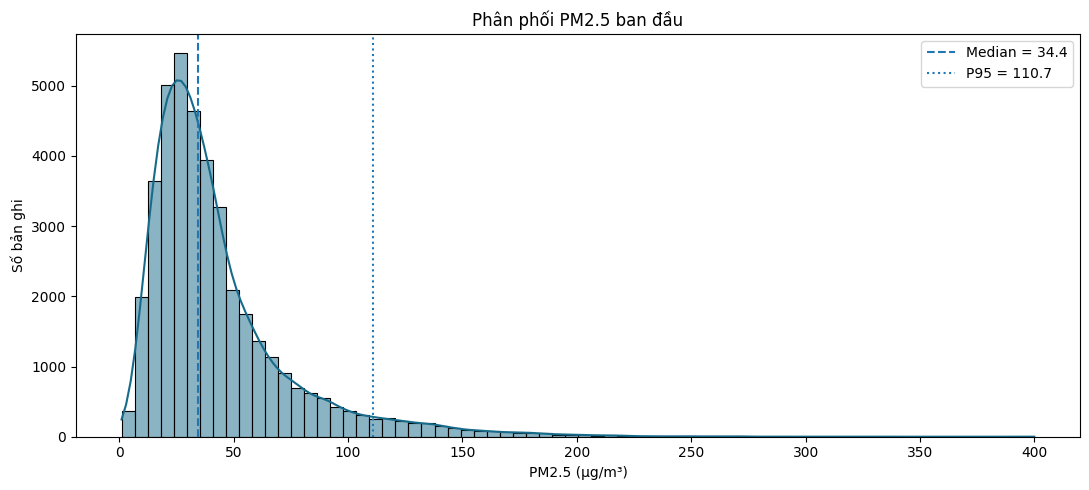

In [14]:
plt.figure(figsize=(11, 5))
sns.histplot(pm25, bins=70, kde=True, color='#176B8A')
plt.axvline(pm25.median(), linestyle='--', label=f'Median = {pm25.median():.1f}')
plt.axvline(pm25.quantile(0.95), linestyle=':', label=f'P95 = {pm25.quantile(0.95):.1f}')
plt.title('Phân phối PM2.5 ban đầu')
plt.xlabel('PM2.5 (µg/m³)')
plt.ylabel('Số bản ghi')
plt.legend()
plt.tight_layout()
plt.show()

In [15]:
peak_cols = [col for col in ['PM25', 'PM10', 'CO', 'NO2', 'O3', 'SO2'] if col in ts.columns]
peak_table = ts[peak_cols].sort_values('PM25', ascending=False).head(15)

print('15 mốc PM2.5 cao nhất:')
display(peak_table)

15 mốc PM2.5 cao nhất:


,PM25,PM10,CO,NO2,O3,SO2
Local Time,,,,,,
2024-02-07 19:00:00,400.000,400.000,403.000,46.000,8.600,74.000
2025-03-20 23:00:00,390.900,452.600,10.000,24.000,2.700,4.000
2025-03-20 22:00:00,380.900,441.700,10.000,23.000,4.300,20.000
2023-12-14 03:00:00,355.500,368.000,202.000,62.000,13.000,58.000
2022-04-08 04:00:00,349.600,485.300,1663.800,65.000,12.000,97.000
2022-04-08 03:00:00,332.400,487.500,1522.200,64.700,17.300,107.300
2025-01-02 23:00:00,331.800,342.300,1210.000,15.000,2.200,32.000
2022-04-08 05:00:00,329.400,483.200,1677.300,53.700,16.700,81.000
2025-01-02 22:00:00,322.600,332.800,2117.000,15.000,1.100,32.000


In [16]:
# Rolling median và Z-score trên phần dư PM2.5
rolling_median = ts['PM25'].rolling(window=24, center=True, min_periods=6).median()
residual = ts['PM25'] - rolling_median

residual_std = residual.std()
if pd.notna(residual_std) and residual_std > 0:
    z_score = (residual - residual.mean()) / residual_std
else:
    z_score = pd.Series(np.nan, index=ts.index)

outlier_flag = (z_score.abs() > 3) & ts['PM25'].notna()

print('Số điểm nghi ngờ outlier (|z| > 3):', int(outlier_flag.sum()))

outlier_table = ts.loc[outlier_flag, ['PM25', 'PM10']].copy()
outlier_table['Rolling Median 24h'] = rolling_median.loc[outlier_flag]
outlier_table['Z-score'] = z_score.loc[outlier_flag]

print('15 điểm có |Z-score| cao nhất:')
display(outlier_table.reindex(z_score.loc[outlier_flag].abs().sort_values(ascending=False).index).head(15))

Số điểm nghi ngờ outlier (|z| > 3): 921
15 điểm có |Z-score| cao nhất:


,PM25,PM10,Rolling Median 24h,Z-score
Local Time,,,,
2024-02-07 19:00:00,400.000,400.000,26.300,20.651
2023-12-14 03:00:00,355.500,368.000,72.500,15.616
2025-03-20 23:00:00,390.900,452.600,111.500,15.416
2025-03-20 22:00:00,380.900,441.700,111.500,14.860
2024-05-17 09:00:00,235.700,355.200,32.900,11.163
2025-06-24 17:00:00,230.900,267.400,30.500,11.029
2025-06-02 23:00:00,214.900,249.500,21.000,10.668
2024-04-28 02:00:00,243.800,326.200,51.100,10.602
2024-05-14 08:00:00,225.600,334.200,35.900,10.435


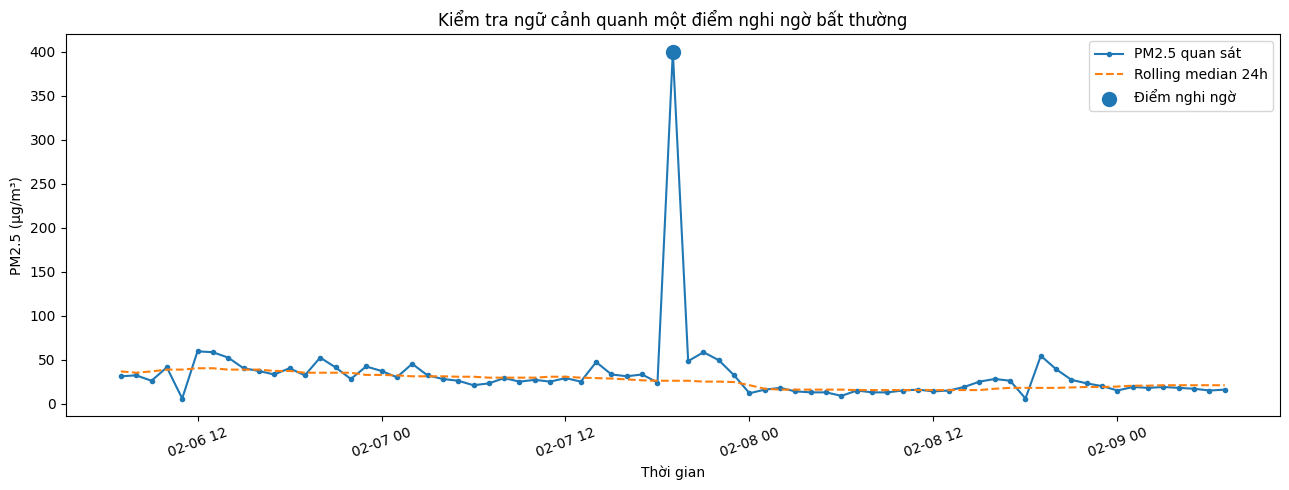

In [17]:
# Vẽ một đoạn thời gian xung quanh điểm nghi ngờ mạnh nhất
if outlier_flag.any():
    candidate_time = z_score.abs().idxmax()
    plot_start = candidate_time - pd.Timedelta(hours=36)
    plot_end = candidate_time + pd.Timedelta(hours=36)
    window_pm25 = ts.loc[plot_start:plot_end, 'PM25']
    window_median = rolling_median.loc[plot_start:plot_end]

    plt.figure(figsize=(13, 5))
    plt.plot(window_pm25.index, window_pm25, marker='.', label='PM2.5 quan sát')
    plt.plot(window_median.index, window_median, linestyle='--', label='Rolling median 24h')
    plt.scatter([candidate_time], [ts.loc[candidate_time, 'PM25']], s=100, label='Điểm nghi ngờ')
    plt.title('Kiểm tra ngữ cảnh quanh một điểm nghi ngờ bất thường')
    plt.xlabel('Thời gian')
    plt.ylabel('PM2.5 (µg/m³)')
    plt.xticks(rotation=20)
    plt.legend()
    plt.tight_layout()
    plt.show()
else:
    print('Không phát hiện điểm vượt ngưỡng Z-score khảo sát.')

## 4.2 PM2.5 có vượt PM10 không

In [18]:
pm_pair = ts[['PM25', 'PM10']].dropna()

n_gt = int((pm_pair['PM25'] > pm_pair['PM10']).sum())
n_eq = int((pm_pair['PM25'] == pm_pair['PM10']).sum())

print(f'Giờ PM2.5 > PM10 : {n_gt} ({n_gt / len(pm_pair) * 100:.2f}%)')
print(f'Giờ PM2.5 = PM10 : {n_eq} ({n_eq / len(pm_pair) * 100:.2f}%)')

print('\nCác giá trị PM2.5 lặp lại nhiều nhất trong vùng >= 250 µg/m³ (dấu hiệu chặn trần):')
display(ts.loc[ts['PM25'] >= 250, 'PM25'].value_counts().head(5).to_frame('Số giờ'))

suspicious = pm_pair[pm_pair['PM25'] >= pm_pair['PM10']]
print('\n10 mốc cao nhất có PM2.5 >= PM10:')
display(suspicious.sort_values('PM25', ascending=False).head(10))

# Điểm rơi đột ngột giữa một đợt cao (z âm rất lớn), ví dụ 2024-02-02 04:00
print('\n5 điểm rơi đột ngột mạnh nhất so với median 24 giờ:')
drop_table = pd.DataFrame({'PM25': ts['PM25'], 'Rolling Median 24h': rolling_median, 'Z-score': z_score})
display(drop_table.loc[z_score < -5].sort_values('Z-score').head(5))

Giờ PM2.5 > PM10 : 1 (0.00%)
Giờ PM2.5 = PM10 : 40 (0.10%)

Các giá trị PM2.5 lặp lại nhiều nhất trong vùng >= 250 µg/m³ (dấu hiệu chặn trần):


,Số giờ
PM25,
268.800,3
258.300,2
270.100,2
251.600,1
274.100,1



10 mốc cao nhất có PM2.5 >= PM10:


,PM25,PM10
Local Time,,
2024-02-07 19:00:00,400.000,400.000
2025-12-13 06:00:00,290.200,290.200
2025-01-03 00:00:00,258.300,258.300
2025-01-03 08:00:00,240.100,240.100
2025-01-03 01:00:00,236.100,236.100
2025-01-03 07:00:00,225.000,225.000
2025-01-03 06:00:00,220.900,220.900
2025-01-03 03:00:00,218.900,218.900
2025-01-03 02:00:00,218.900,218.900



5 điểm rơi đột ngột mạnh nhất so với median 24 giờ:


,PM25,Rolling Median 24h,Z-score
Local Time,,,
2024-02-02 04:00:00,22.800,204.600,-10.192
2022-04-07 13:00:00,35.400,188.450,-8.595
2022-04-07 14:00:00,40.400,188.450,-8.318
2023-11-19 17:00:00,24.800,168.250,-8.062
2022-04-07 15:00:00,45.500,188.450,-8.035


# V. PM2.5 biến động theo thời gian như thế nào?

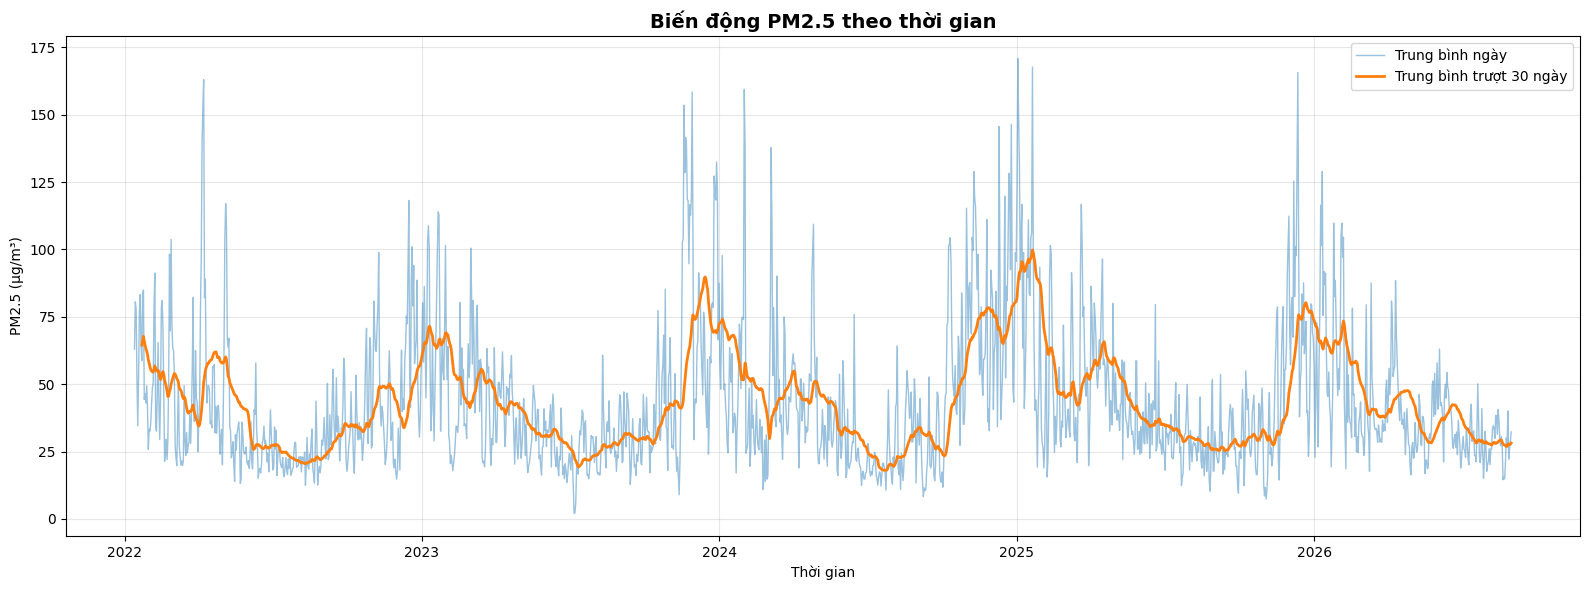

In [19]:
daily_pm25 = ts['PM25'].resample('D').mean()
monthly_pm25 = ts['PM25'].resample('MS').mean()

plt.figure(figsize=(16, 6))
plt.plot(daily_pm25.index, daily_pm25.values, alpha=0.45, linewidth=1, label='Trung bình ngày')
plt.plot(daily_pm25.rolling(30, min_periods=10).mean(), linewidth=2, label='Trung bình trượt 30 ngày')

plt.title('Biến động PM2.5 theo thời gian', fontsize=14, fontweight='bold')
plt.xlabel('Thời gian')
plt.ylabel('PM2.5 (µg/m³)')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 5.1 Median và IQR theo tháng

In [20]:
month_profile = pd.DataFrame({'month': ts.index.month, 'PM25': ts['PM25'].values}).dropna()
month_stats = month_profile.groupby('month')['PM25'].agg(
    median='median',
    q25=lambda x: x.quantile(0.25),
    q75=lambda x: x.quantile(0.75),
    mean='mean'
)

display(month_stats)


,median,q25,q75,mean
month,,,,
1,56.900,39.000,84.900,66.394
2,35.400,26.000,52.500,45.004
3,37.600,28.000,56.000,45.764
4,43.400,33.300,58.775,50.994
5,30.000,21.500,40.000,34.639
6,26.000,18.000,38.000,30.831
7,23.000,16.100,31.300,24.850
8,24.300,17.200,34.400,27.084
9,26.300,18.000,37.400,29.509


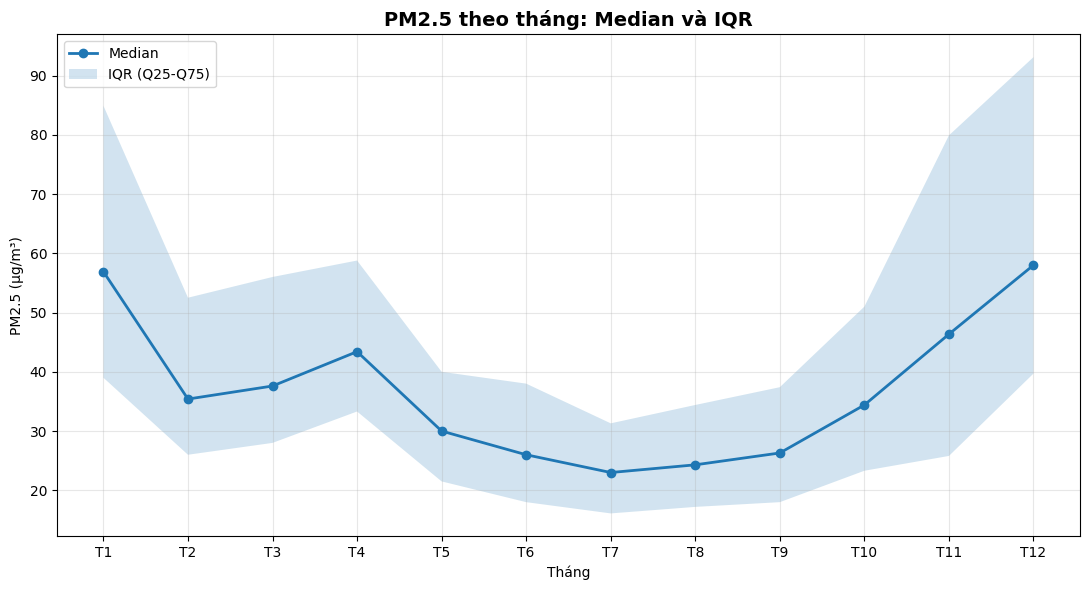

In [21]:
plt.figure(figsize=(11, 6))

plt.plot(month_stats.index, month_stats['median'], marker='o', linewidth=2, label='Median')

plt.fill_between(month_stats.index, month_stats['q25'], month_stats['q75'], alpha=0.2, label='IQR (Q25-Q75)')

plt.xticks(range(1, 13), [f'T{i}' for i in range(1, 13)])
plt.title('PM2.5 theo tháng: Median và IQR', fontsize=14, fontweight='bold')
plt.xlabel('Tháng')
plt.ylabel('PM2.5 (µg/m³)')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# VI. PM2.5 có quy luật theo giờ, ngày và mùa không?

In [22]:
eda_time = ts[['PM25']].copy()

eda_time['Hour'] = eda_time.index.hour
eda_time['DayOfWeek'] = eda_time.index.dayofweek
eda_time['Month'] = eda_time.index.month
eda_time['Year'] = eda_time.index.year

def get_season(month):
    if month in [12, 1, 2]:
        return 'Đông'
    elif month in [3, 4, 5]:
        return 'Xuân'
    elif month in [6, 7, 8]:
        return 'Hạ'
    return 'Thu'

eda_time['Season'] = eda_time['Month'].apply(get_season)

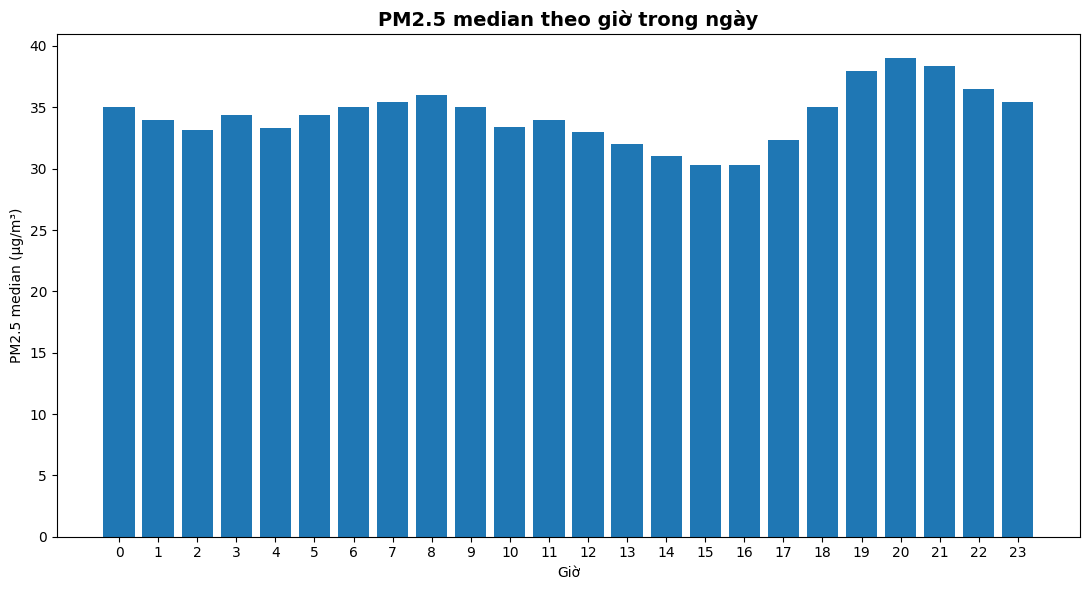

In [23]:
hourly_pm25 = eda_time.groupby('Hour')['PM25'].median()

plt.figure(figsize=(11, 6))
bars = plt.bar(hourly_pm25.index, hourly_pm25.values)

plt.title('PM2.5 median theo giờ trong ngày', fontsize=14, fontweight='bold')
plt.xlabel('Giờ')
plt.ylabel('PM2.5 median (µg/m³)')
plt.xticks(range(24))
plt.tight_layout()
plt.show()


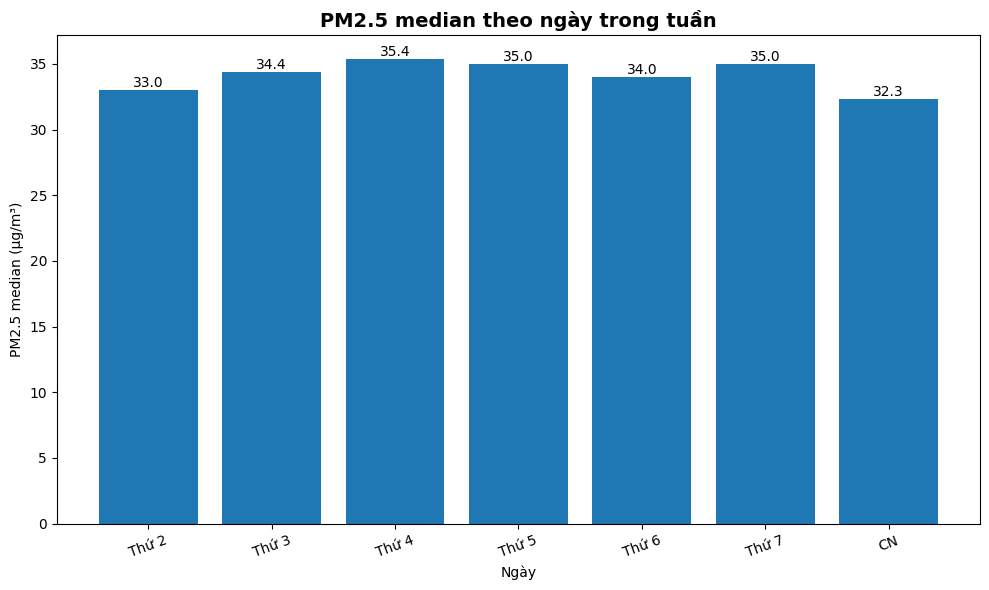

In [24]:
day_names = ['Thứ 2', 'Thứ 3', 'Thứ 4', 'Thứ 5', 'Thứ 6', 'Thứ 7', 'CN']

dow_pm25 = eda_time.groupby('DayOfWeek')['PM25'].median()
dow_pm25.index = day_names

plt.figure(figsize=(10, 6))
bars = plt.bar(dow_pm25.index, dow_pm25.values)

plt.title('PM2.5 median theo ngày trong tuần', fontsize=14, fontweight='bold')
plt.xlabel('Ngày')
plt.ylabel('PM2.5 median (µg/m³)')
plt.xticks(rotation=20)

for bar in bars:
    value = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, value, f'{value:.1f}', ha='center', va='bottom')

plt.tight_layout()
plt.show()

In [25]:
weekday_median = eda_time.loc[eda_time['DayOfWeek'] < 5, 'PM25'].median()
weekend_median = eda_time.loc[eda_time['DayOfWeek'] >= 5, 'PM25'].median()

print(f'Chênh giữa ngày cao nhất và thấp nhất: {dow_pm25.max() - dow_pm25.min():.1f} µg/m³')
print(f'Ngày thường: {weekday_median:.1f} | Cuối tuần: {weekend_median:.1f}')

Chênh giữa ngày cao nhất và thấp nhất: 3.1 µg/m³
Ngày thường: 34.4 | Cuối tuần: 34.0


,mean,median
Season,,
Xuân,43.721,36.500
Hạ,27.553,24.200
Thu,43.742,33.300
Đông,60.324,49.000


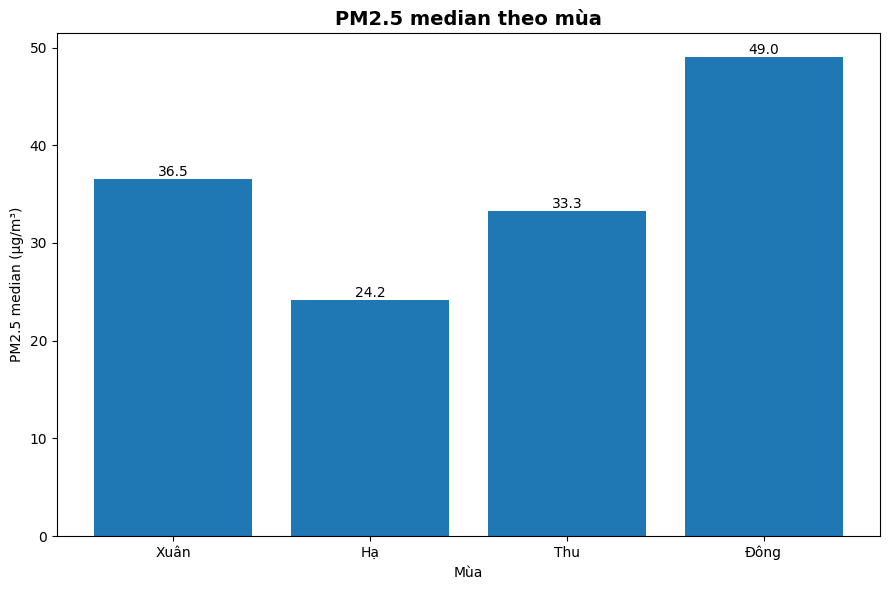

In [26]:
season_order = ['Xuân', 'Hạ', 'Thu', 'Đông']

season_stats = eda_time.groupby('Season')['PM25'].agg(mean='mean', median='median').reindex(season_order)

display(season_stats)

plt.figure(figsize=(9, 6))
bars = plt.bar(season_stats.index, season_stats['median'])

plt.title('PM2.5 median theo mùa', fontsize=14, fontweight='bold')
plt.xlabel('Mùa')
plt.ylabel('PM2.5 median (µg/m³)')

for bar in bars:
    value = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, value, f'{value:.1f}', ha='center', va='bottom')

plt.tight_layout()
plt.show()

## 6.1 Heatmap Hour × Month

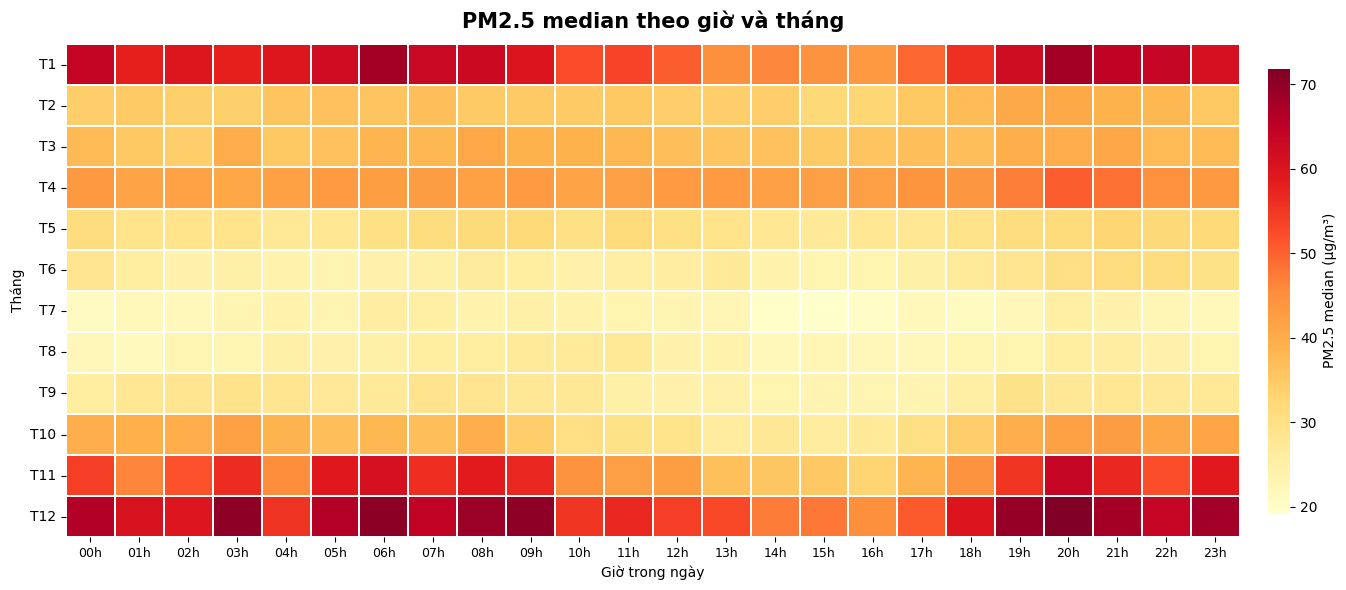

In [27]:
hour_month = eda_time.pivot_table(index='Month', columns='Hour', values='PM25', aggfunc='median')

plt.figure(figsize=(15, 6))
ax = sns.heatmap(hour_month, cmap='YlOrRd', linewidths=0.35, linecolor='white',
                 cbar_kws={'label': 'PM2.5 median (µg/m³)', 'shrink': 0.9, 'pad': 0.02})

ax.set_title('PM2.5 median theo giờ và tháng', fontsize=15, fontweight='bold', pad=12)
ax.set_xlabel('Giờ trong ngày')
ax.set_ylabel('Tháng')
ax.set_xticklabels([f'{h:02d}h' for h in hour_month.columns], rotation=0, fontsize=9)
ax.set_yticklabels([f'T{m}' for m in hour_month.index], rotation=0)

plt.tight_layout()
plt.show()


## 6.2 Xác suất gặp PM2.5 cao theo giờ và tháng

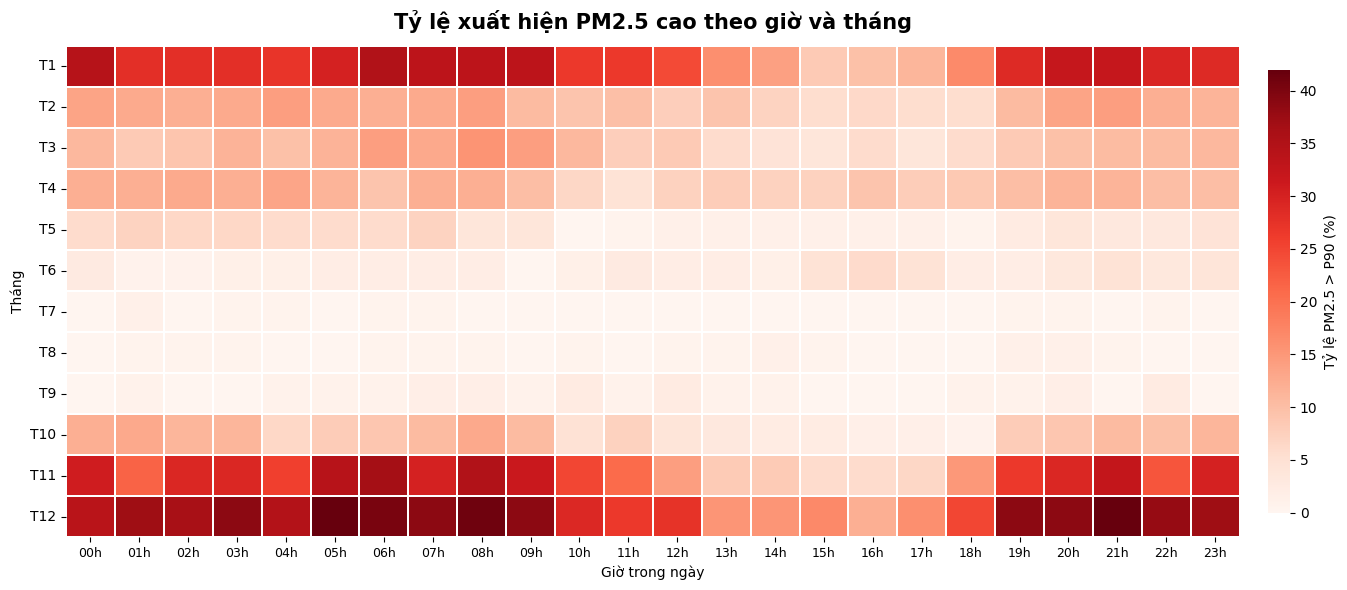

In [28]:
high_threshold = pm25.quantile(0.90)

high_pattern = eda_time.copy()
high_pattern['High_PM25'] = high_pattern['PM25'] > high_threshold
high_rate = high_pattern.pivot_table(index='Month', columns='Hour', values='High_PM25', aggfunc='mean') * 100

plt.figure(figsize=(15, 6))
ax = sns.heatmap(high_rate, cmap='Reds', linewidths=0.35, linecolor='white',
                 cbar_kws={'label': 'Tỷ lệ PM2.5 > P90 (%)', 'shrink': 0.9, 'pad': 0.02})

ax.set_title('Tỷ lệ xuất hiện PM2.5 cao theo giờ và tháng', fontsize=15, fontweight='bold', pad=12)
ax.set_xlabel('Giờ trong ngày')
ax.set_ylabel('Tháng')
ax.set_xticklabels([f'{h:02d}h' for h in high_rate.columns], rotation=0, fontsize=9)
ax.set_yticklabels([f'T{m}' for m in high_rate.index], rotation=0)

plt.tight_layout()
plt.show()


## 6.3 Ngày lễ có làm PM2.5 thay đổi không

In [29]:
# VN_HOLIDAYS nạp từ src/vn_holidays.py ở ô import, dùng chung với 05_features

holiday_df = eda_time[['PM25', 'Year', 'Month']].copy()
holiday_df['IsHoliday'] = holiday_df.index.strftime('%Y-%m-%d').isin(VN_HOLIDAYS)

# Chỉ giữ các tháng có ngày lễ, so median ngày lễ với median ngày thường cùng tháng
holiday_cmp = (holiday_df.groupby(['Year', 'Month', 'IsHoliday'])['PM25']
               .median().unstack('IsHoliday').dropna())
holiday_cmp.columns = ['Ngày thường', 'Ngày lễ']
holiday_cmp['Chênh (lễ - thường)'] = holiday_cmp['Ngày lễ'] - holiday_cmp['Ngày thường']

display(holiday_cmp.round(1))
print('Số tháng có ngày lễ:', len(holiday_cmp))
print('Số tháng ngày lễ thấp hơn ngày thường:', int((holiday_cmp['Chênh (lễ - thường)'] < 0).sum()))
print(f"Trung vị chênh lệch: {holiday_cmp['Chênh (lễ - thường)'].median():.1f} µg/m³")

Ngày thường  Ngày lễ  Chênh (lễ - thường)
Year Month                                           
2022 1           53.500   30.800              -22.700
     2           39.400   38.400               -1.000
     4           40.400   44.500                4.100
     5           29.300   29.800                0.500
     9           32.300   31.300               -1.000
2023 1           58.000   66.600                8.600
     4           40.800   23.600              -17.200
     5           29.000   33.300                4.300
     9           25.800   32.200                6.400
2024 1           46.500   83.900               37.400
     2           27.300   26.300               -1.000
     4           44.500   37.400               -7.100
     5           26.300   23.800               -2.500
     8           29.300   23.300               -6.000
     9           18.200   31.400               13.200
2025 1           82.500   38.000              -44.500
     2           39.000   29.000              -10.000
     4           53.000   56.500                3.500
     5           35.000   33.000               -2.000
     8           25.000   16.500               -8.500
     9           25.000   30.500                5.500
2026 1           59.600   49.500              -10.100
     2           42.000   38.000               -4.000
     4           43.000   27.500              -15.500
     5           29.000   25.000               -4.000
     8           26.000   27.500                1.500

Số tháng có ngày lễ: 26
Số tháng ngày lễ thấp hơn ngày thường: 16
Trung vị chênh lệch: -1.5 µg/m³


# VII. PM2.5 phụ thuộc vào lịch sử của chính nó bao lâu?

In [30]:
lags_check = [1, 3, 6, 12, 24, 48, 72, 168]

acf_rows = []

for lag in lags_check:
    acf_rows.append({'Lag_hour': lag, 'Autocorrelation': ts['PM25'].autocorr(lag=lag)})

acf_table = pd.DataFrame(acf_rows)
display(acf_table)

,Lag_hour,Autocorrelation
0,1,0.881
1,3,0.766
2,6,0.639
3,12,0.520
4,24,0.589
5,48,0.455
6,72,0.378
7,168,0.263


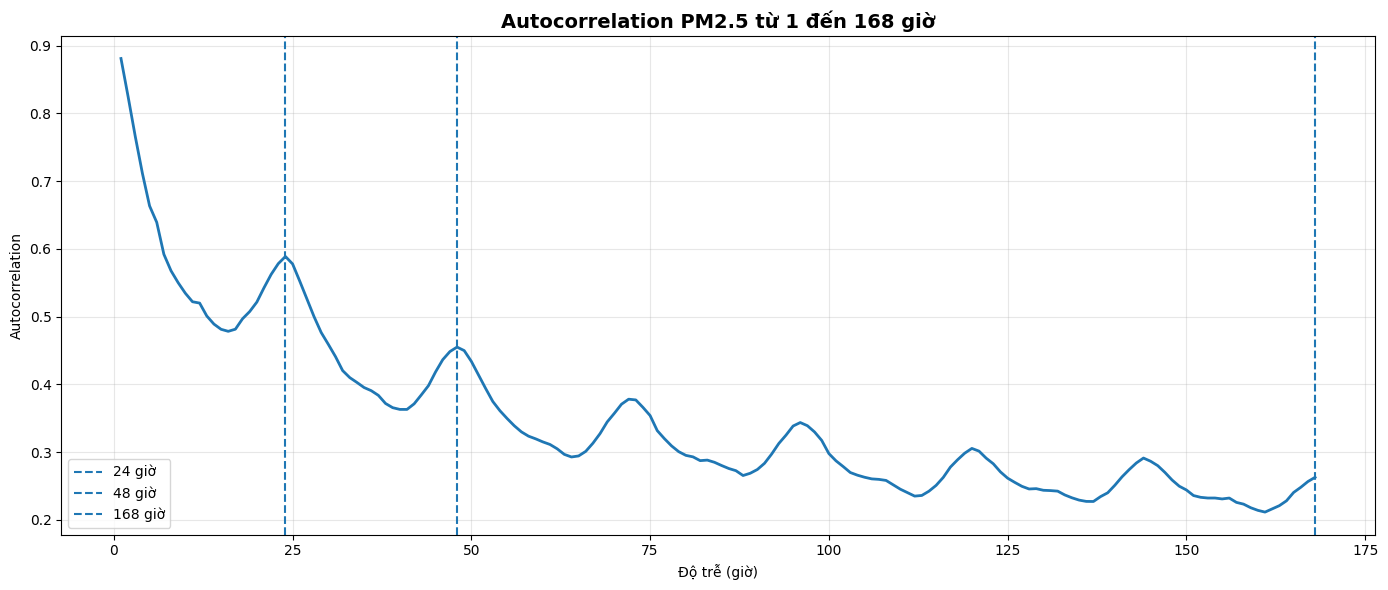

In [31]:
acf_all = []

for lag in range(1, 169):
    acf_all.append(ts['PM25'].autocorr(lag=lag))

plt.figure(figsize=(14, 6))
plt.plot(range(1, 169), acf_all, linewidth=2)

plt.axvline(24, linestyle='--', label='24 giờ')
plt.axvline(48, linestyle='--', label='48 giờ')
plt.axvline(168, linestyle='--', label='168 giờ')

plt.title('Autocorrelation PM2.5 từ 1 đến 168 giờ',
          fontsize=14, fontweight='bold')
plt.xlabel('Độ trễ (giờ)')
plt.ylabel('Autocorrelation')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


## 7.1 ACF sau khi loại mùa vụ và chu kỳ ngày

,Lag_hour,ACF_goc,ACF_sau_loai_mua
0,1,0.881,0.851
1,3,0.766,0.718
2,6,0.639,0.577
3,12,0.520,0.417
4,24,0.589,0.471
5,48,0.455,0.298
6,72,0.378,0.200
7,168,0.263,0.052


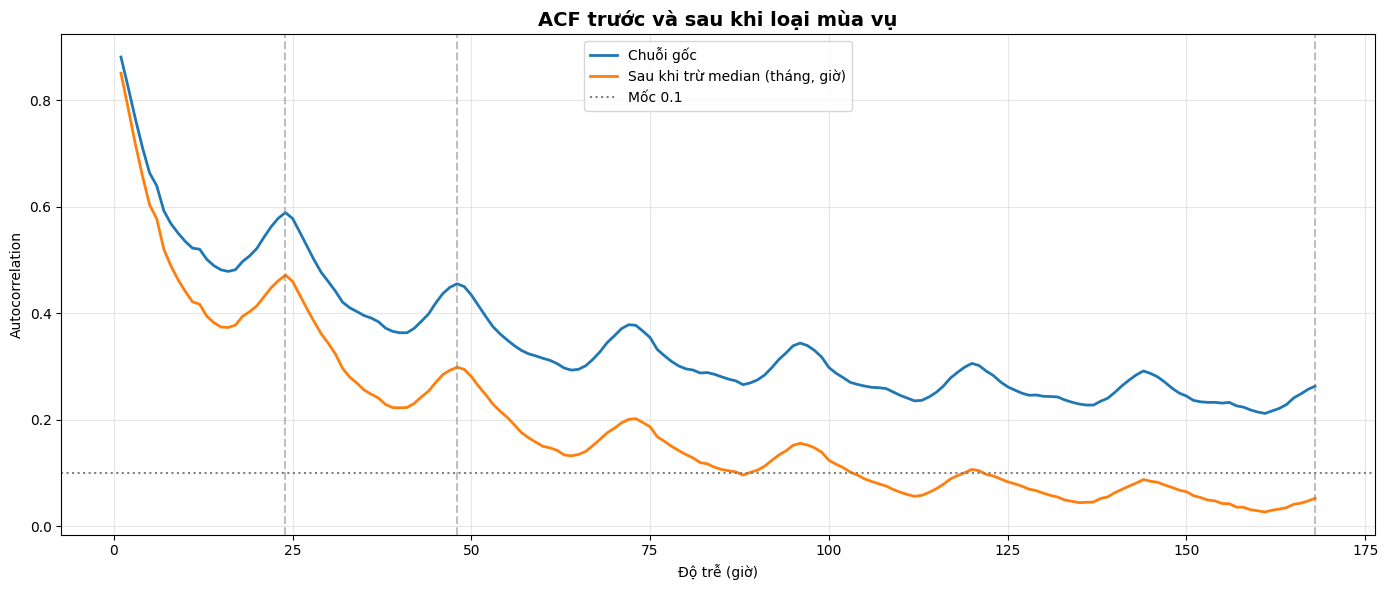

Lag đầu tiên ACF sau loại mùa xuống dưới 0.1: 88


In [32]:
pm25_anom = ts['PM25'] - ts.groupby([ts.index.month, ts.index.hour])['PM25'].transform('median')

acf_compare = pd.DataFrame({
    'Lag_hour': lags_check,
    'ACF_goc': [ts['PM25'].autocorr(lag=l) for l in lags_check],
    'ACF_sau_loai_mua': [pm25_anom.autocorr(lag=l) for l in lags_check],
})
display(acf_compare.round(3))

acf_anom_all = [pm25_anom.autocorr(lag=l) for l in range(1, 169)]

plt.figure(figsize=(14, 6))
plt.plot(range(1, 169), acf_all, linewidth=2, label='Chuỗi gốc')
plt.plot(range(1, 169), acf_anom_all, linewidth=2, label='Sau khi trừ median (tháng, giờ)')
plt.axhline(0.1, linestyle=':', color='grey', label='Mốc 0.1')
for lag in (24, 48, 168):
    plt.axvline(lag, linestyle='--', color='grey', alpha=0.5)
plt.title('ACF trước và sau khi loại mùa vụ', fontsize=14, fontweight='bold')
plt.xlabel('Độ trễ (giờ)')
plt.ylabel('Autocorrelation')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

below = [l for l, v in zip(range(1, 169), acf_anom_all) if v < 0.1]
print('Lag đầu tiên ACF sau loại mùa xuống dưới 0.1:', below[0] if below else 'không xuống dưới 0.1 trong 168 giờ')

# VIII. Forecast horizon càng xa thì bài toán khó lên như thế nào?

In [33]:
horizons = [1, 3, 6, 12, 24, 48, 72]

forecast_rows = []

for h in horizons:
    diff = (ts['PM25'].shift(-h) - ts['PM25']).abs().dropna()

    forecast_rows.append({
        'Horizon_h': h,
        'Mean_abs_change': diff.mean(),
        'Median_abs_change': diff.median(),
        'P90_abs_change': diff.quantile(0.90)
    })

forecast_change = pd.DataFrame(forecast_rows)
display(forecast_change)


,Horizon_h,Mean_abs_change,Median_abs_change,P90_abs_change
0,1,8.154,4.000,18.300
1,3,13.058,7.100,30.300
2,6,16.989,10.000,40.000
3,12,20.146,12.000,48.000
4,24,18.931,11.800,44.100
5,48,22.567,14.200,52.600
6,72,24.288,15.200,57.000


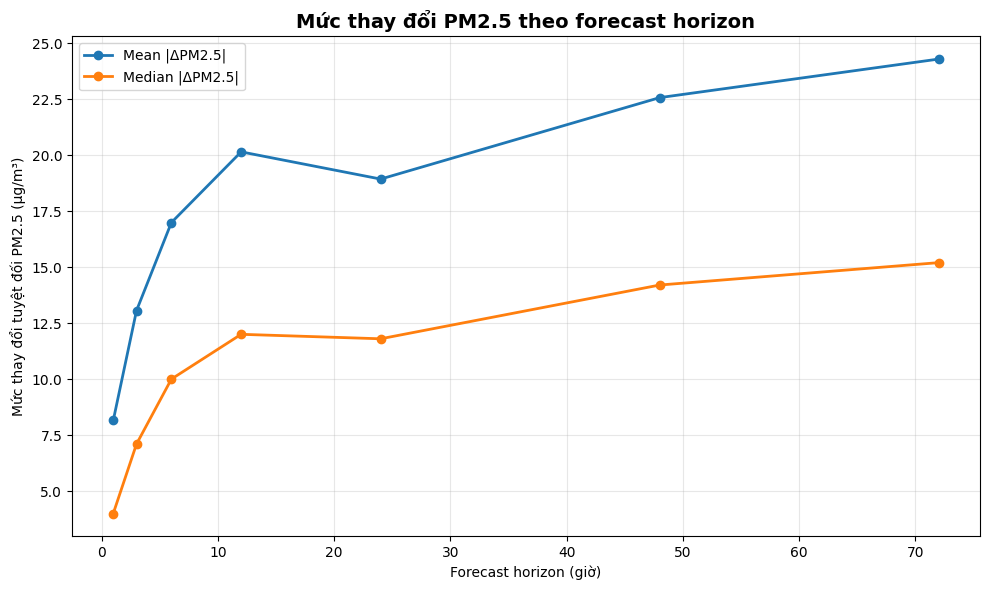

In [34]:
plt.figure(figsize=(10, 6))

plt.plot(forecast_change['Horizon_h'], forecast_change['Mean_abs_change'], marker='o', linewidth=2, label='Mean |ΔPM2.5|')

plt.plot(forecast_change['Horizon_h'], forecast_change['Median_abs_change'], marker='o', linewidth=2, label='Median |ΔPM2.5|')

plt.title('Mức thay đổi PM2.5 theo forecast horizon', fontsize=14, fontweight='bold')
plt.xlabel('Forecast horizon (giờ)')
plt.ylabel('Mức thay đổi tuyệt đối PM2.5 (µg/m³)')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# IX. Các chất ô nhiễm khác có chứa thông tin cho PM2.5 tương lai không?

In [35]:
pollutants = ['PM10', 'CO', 'NO2', 'SO2', 'O3']

same_corr = (
    ts[pollutants + ['PM25']]
    .corr(method='spearman')['PM25']
    .drop('PM25')
    .sort_values(key=abs, ascending=False)
)

display(same_corr.to_frame('Spearman_same_time'))


,Spearman_same_time
PM10,0.953
NO2,0.195
SO2,0.192
CO,0.115
O3,-0.042


In [36]:
future_horizons = [3, 6, 12, 24]

pollutant_future_corr = pd.DataFrame(
    index=pollutants,
    columns=[f'+{h}h' for h in future_horizons],
    dtype=float
)

for col in pollutants:
    for h in future_horizons:
        temp = pd.concat(
            [ts[col], ts['PM25'].shift(-h)],
            axis=1
        ).dropna()

        temp.columns = ['X', 'PM25_future']

        pollutant_future_corr.loc[col, f'+{h}h'] = (
            temp['X'].corr(temp['PM25_future'], method='spearman')
        )

display(pollutant_future_corr.round(3))


,+3h,+6h,+12h,+24h
PM10,0.755,0.653,0.555,0.566
CO,0.116,0.084,0.068,0.084
NO2,0.178,0.128,0.096,0.133
SO2,0.186,0.178,0.152,0.158
O3,-0.013,0.020,0.025,-0.041


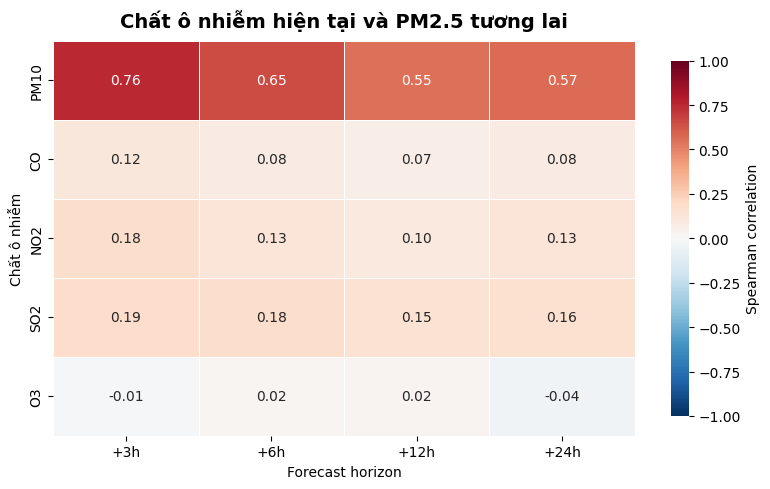

In [37]:
plt.figure(figsize=(8, 5))
ax = sns.heatmap(pollutant_future_corr.astype(float), annot=True, fmt='.2f', cmap='RdBu_r',
                 center=0, vmin=-1, vmax=1, linewidths=0.5,
                 cbar_kws={'label': 'Spearman correlation', 'shrink': 0.9})

ax.set_title('Chất ô nhiễm hiện tại và PM2.5 tương lai', fontsize=14, fontweight='bold', pad=10)
ax.set_xlabel('Forecast horizon')
ax.set_ylabel('Chất ô nhiễm')

plt.tight_layout()
plt.show()


# X. Khí tượng liên hệ với PM2.5 như thế nào?

## 10.1 Quan hệ cùng thời điểm

In [38]:
weather_cols = [
    'Temperature',
    'Relative Humidity',
    'Precipitation',
    'Clouds',
    'Pressure',
    'UV Index',
    'Wind Speed',
    'Solar Radiation'
]

weather_cols = [c for c in weather_cols if c in ts.columns]
weather_corr = (ts[weather_cols + ['PM25']] .corr(method='spearman')['PM25'] .drop('PM25') .sort_values(key=abs, ascending=False))

display(weather_corr.to_frame('Spearman_PM25'))


,Spearman_PM25
Pressure,0.362
Temperature,-0.321
Precipitation,-0.204
Wind Speed,-0.182
Solar Radiation,-0.091
Relative Humidity,-0.069
UV Index,-0.068
Clouds,-0.061


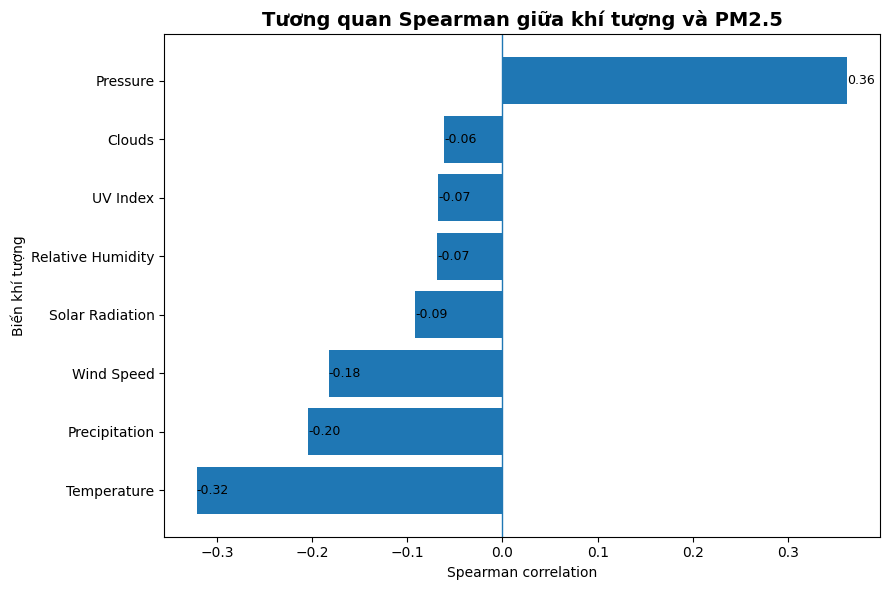

In [39]:
plt.figure(figsize=(9, 6))

ordered = weather_corr.sort_values()

plt.barh(ordered.index, ordered.values)
plt.axvline(0, linewidth=1)

for i, v in enumerate(ordered.values):
    plt.text(v, i, f'{v:.2f}', va='center', fontsize=9)
plt.title('Tương quan Spearman giữa khí tượng và PM2.5',
          fontsize=14, fontweight='bold')

plt.xlabel('Spearman correlation')
plt.ylabel('Biến khí tượng')
plt.tight_layout()
plt.show()


## 10.2 Weather hiện tại có liên hệ với PM2.5 tương lai không?

In [40]:
weather_future_corr = pd.DataFrame(index=weather_cols, columns=[f'+{h}h' for h in future_horizons], dtype=float)

for col in weather_cols:
    for h in future_horizons:
        temp = pd.concat([ts[col], ts['PM25'].shift(-h)], axis=1).dropna()

        temp.columns = ['X', 'PM25_future']

        weather_future_corr.loc[col, f'+{h}h'] = (temp['X'].corr(temp['PM25_future'], method='spearman'))

display(weather_future_corr.round(3))

,+3h,+6h,+12h,+24h
Temperature,-0.319,-0.307,-0.319,-0.382
Relative Humidity,-0.089,-0.136,-0.178,-0.139
Precipitation,-0.216,-0.212,-0.201,-0.182
Clouds,-0.069,-0.073,-0.071,-0.051
Pressure,0.354,0.361,0.398,0.432
UV Index,-0.074,-0.023,0.043,-0.066
Wind Speed,-0.211,-0.192,-0.135,-0.142
Solar Radiation,-0.095,-0.045,0.023,-0.085


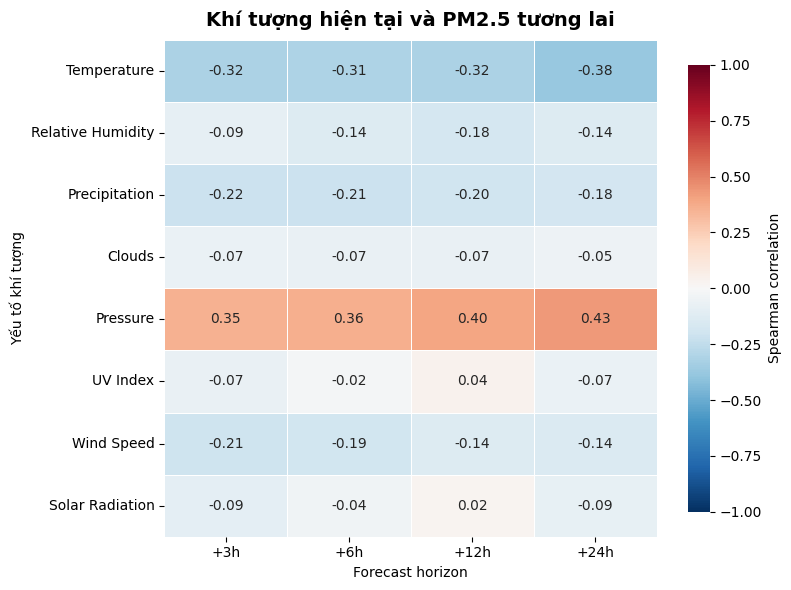

In [41]:
plt.figure(figsize=(8, 6))
ax = sns.heatmap(weather_future_corr.astype(float), annot=True, fmt='.2f', cmap='RdBu_r',
                 center=0, vmin=-1, vmax=1, linewidths=0.5,
                 cbar_kws={'label': 'Spearman correlation', 'shrink': 0.9})

ax.set_title('Khí tượng hiện tại và PM2.5 tương lai', fontsize=14, fontweight='bold', pad=10)
ax.set_xlabel('Forecast horizon')
ax.set_ylabel('Yếu tố khí tượng')

plt.tight_layout()
plt.show()


## 10.3 Quan hệ có dấu hiệu phi tuyến không?


 Wind Speed


,X_median,PM25_median,PM25_mean,N
Group,,,,
"(-0.001, 1.0]",0.800,39.000,50.274,10115
"(1.0, 1.6]",1.330,38.700,50.882,6676
"(1.6, 2.0]",2.000,33.300,41.310,11625
"(2.0, 2.66]",2.360,31.000,36.923,5389
"(2.66, 28.33]",3.000,30.000,34.143,6803


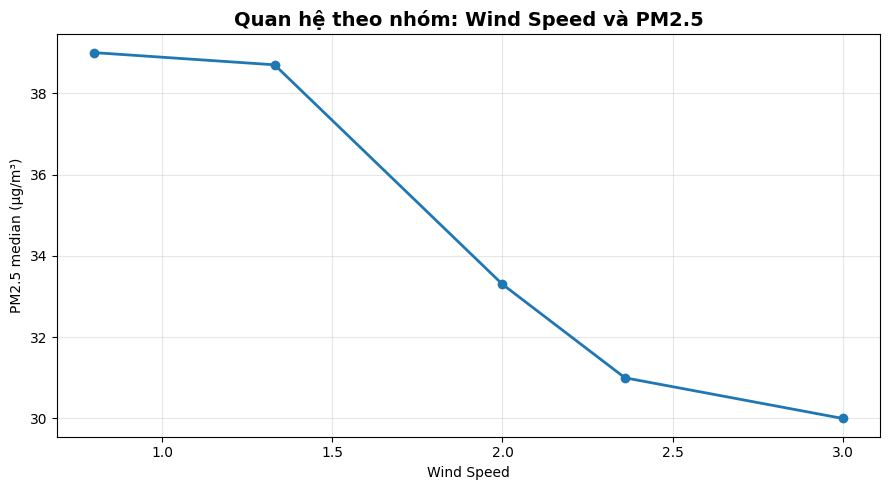


 Pressure


,X_median,PM25_median,PM25_mean,N
Group,,,,
"(982.999, 1003.0]",1001.000,27.300,31.493,9589
"(1003.0, 1007.0]",1005.000,28.000,31.910,8131
"(1007.0, 1012.0]",1010.000,33.400,39.967,8336
"(1012.0, 1016.0]",1014.000,45.600,57.454,6507
"(1016.0, 1033.0]",1020.000,49.600,61.059,8045


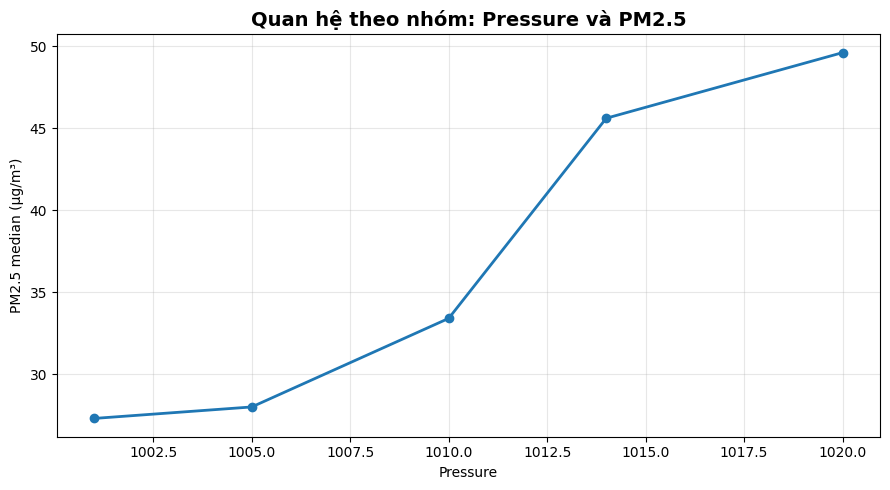


 Temperature


,X_median,PM25_median,PM25_mean,N
Group,,,,
"(6.999, 20.0]",17.200,49.500,60.573,8283
"(20.0, 24.5]",22.500,41.400,53.381,8184
"(24.5, 27.1]",26.000,31.100,36.373,8116
"(27.1, 29.7]",28.400,29.000,32.613,8073
"(29.7, 41.1]",31.800,29.000,33.024,7952


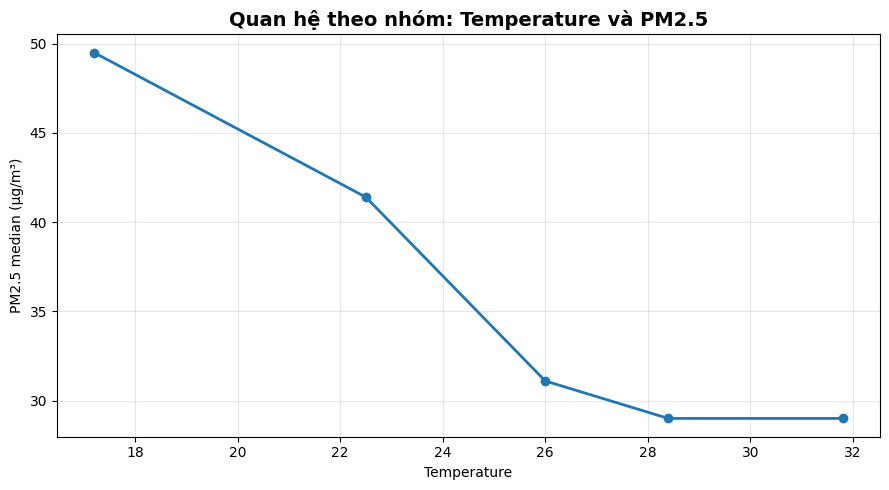


 Relative Humidity


,X_median,PM25_median,PM25_mean,N
Group,,,,
"(16.999, 66.0]",57.000,35.200,43.628,8628
"(66.0, 78.0]",73.000,36.000,45.446,8062
"(78.0, 87.0]",84.000,35.400,44.712,8760
"(87.0, 92.0]",90.000,33.000,41.737,7553
"(92.0, 100.0]",94.000,31.400,40.759,7605


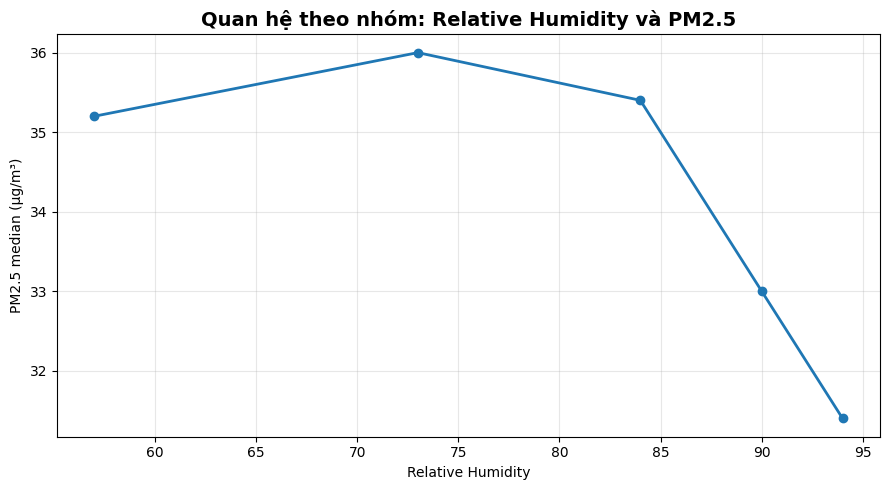

In [42]:
check_cols = [c for c in ['Wind Speed', 'Pressure', 'Temperature', 'Relative Humidity'] if c in ts.columns]

for col in check_cols:
    temp = ts[[col, 'PM25']].dropna().copy()

    temp['Group'] = pd.qcut(temp[col], q=5, duplicates='drop')

    summary = temp.groupby(
        'Group',
        observed=False
    ).agg(
        X_median=(col, 'median'),
        PM25_median=('PM25', 'median'),
        PM25_mean=('PM25', 'mean'),
        N=('PM25', 'size')
    )

    print('\n', col)
    display(summary)

    plt.figure(figsize=(9, 5))
    plt.plot(summary['X_median'], summary['PM25_median'], marker='o', linewidth=2)

    plt.title(f'Quan hệ theo nhóm: {col} và PM2.5', fontsize=14, fontweight='bold')
    plt.xlabel(col)
    plt.ylabel('PM2.5 median (µg/m³)')
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

## 10.4 Correlation sau khi giảm ảnh hưởng mùa vụ

In [43]:
# Tạo anomaly bằng cách trừ median của từng tháng trong năm
anomaly_cols = ['PM25'] + weather_cols
anomaly_df = ts[anomaly_cols].copy()

month_number = anomaly_df.index.month

for col in anomaly_cols:
    monthly_median = anomaly_df.groupby(month_number)[col].transform('median')
    anomaly_df[col + '_anom'] = anomaly_df[col] - monthly_median

anomaly_corr = {}

for col in weather_cols:
    temp = anomaly_df[[col + '_anom', 'PM25_anom']].dropna()
    anomaly_corr[col] = temp[col + '_anom'].corr(temp['PM25_anom'], method='spearman')

anomaly_corr = pd.Series(anomaly_corr).sort_values(key=abs, ascending=False)

comparison_corr = pd.DataFrame({'Corr_goc': weather_corr, 'Corr_sau_khi_tru_median_thang': anomaly_corr})

display(comparison_corr.round(3))

,Corr_goc,Corr_sau_khi_tru_median_thang
Clouds,-0.061,-0.139
Precipitation,-0.204,-0.082
Pressure,0.362,0.013
Relative Humidity,-0.069,-0.007
Solar Radiation,-0.091,-0.044
Temperature,-0.321,0.021
UV Index,-0.068,-0.035
Wind Speed,-0.182,-0.234


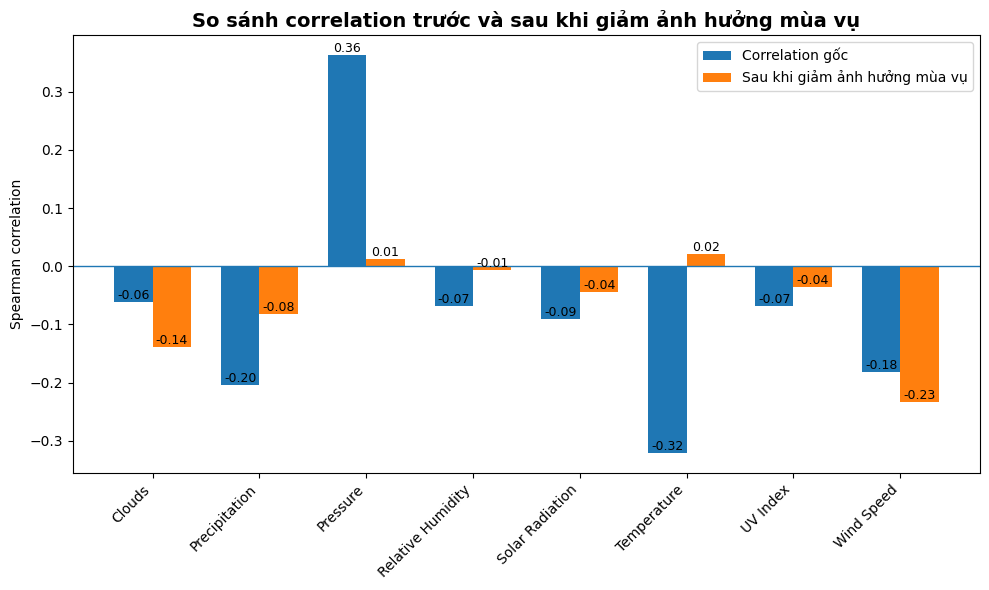

In [44]:
plt.figure(figsize=(10, 6))

x = np.arange(len(comparison_corr.index))
width = 0.36

plt.bar(x - width/2, comparison_corr['Corr_goc'], width=width, label='Correlation gốc')

plt.bar(x + width/2, comparison_corr['Corr_sau_khi_tru_median_thang'], width=width, label='Sau khi giảm ảnh hưởng mùa vụ')

for i, v in enumerate(comparison_corr['Corr_goc']):
    plt.text(i - width/2, v, f'{v:.2f}', ha='center', va='bottom', fontsize=9)

for i, v in enumerate(comparison_corr['Corr_sau_khi_tru_median_thang']):
    plt.text(i + width/2, v, f'{v:.2f}', ha='center', va='bottom', fontsize=9)

plt.axhline(0, linewidth=1)
plt.xticks(x, comparison_corr.index, rotation=45, ha='right')
plt.ylabel('Spearman correlation')
plt.title('So sánh correlation trước và sau khi giảm ảnh hưởng mùa vụ', fontsize=14, fontweight='bold')
plt.legend()
plt.tight_layout()
plt.show()

## 10.4b Kiểm tra lại trên phần đầu chuỗi và kiểm tra áp suất đổi nhanh

In [45]:
# 1. Bảng 10.4 trên 70% đầu chuỗi
train_part = anomaly_df.iloc[:int(len(anomaly_df) * 0.70)].copy()
month_train = train_part.index.month
for col in anomaly_cols:
    train_part[col + '_anom'] = train_part[col] - train_part.groupby(month_train)[col].transform('median')

anomaly_corr_train = pd.Series({
    col: train_part[col + '_anom'].corr(train_part['PM25_anom'], method='spearman')
    for col in weather_cols
})

robust_check = comparison_corr.copy()
robust_check['Sau_tru_mua_70%_dau'] = anomaly_corr_train
print('Từ', train_part.index.min(), 'đến', train_part.index.max())
display(robust_check.round(3))

# 2. Áp suất đổi nhanh và PM2.5 tương lai (đã loại mùa)
pressure_anom_24 = ts['Pressure'].shift(1) - ts['Pressure'].shift(1).rolling(24).mean()

pressure_rows = []
for h in [0] + future_horizons:
    pair = pd.concat([pressure_anom_24, anomaly_df['PM25_anom'].shift(-h)], axis=1).dropna()
    pressure_rows.append({'Horizon': f'+{h}h',
                          'Spearman': pair.iloc[:, 0].corr(pair.iloc[:, 1], method='spearman')})
display(pd.DataFrame(pressure_rows).round(3))

Từ 2022-01-13 00:00:00 đến 2025-04-11 08:00:00


,Corr_goc,Corr_sau_khi_tru_median_thang,Sau_tru_mua_70%_dau
Clouds,-0.061,-0.139,-0.109
Precipitation,-0.204,-0.082,-0.041
Pressure,0.362,0.013,0.039
Relative Humidity,-0.069,-0.007,0.005
Solar Radiation,-0.091,-0.044,-0.064
Temperature,-0.321,0.021,-0.018
UV Index,-0.068,-0.035,-0.051
Wind Speed,-0.182,-0.234,-0.248


,Horizon,Spearman
0,+0h,-0.148
1,+3h,-0.240
2,+6h,-0.221
3,+12h,-0.128
4,+24h,-0.064


## 10.5 Mưa cần phân tích riêng

,N,Rain_median,PM25_median,PM25_mean
Rain_group,,,,
Không mưa,31737,0.000,36.400,45.931
Mưa thấp,4091,0.500,29.300,36.587
Mưa vừa,2305,1.000,29.000,35.748
Mưa cao,2475,2.500,22.300,28.237


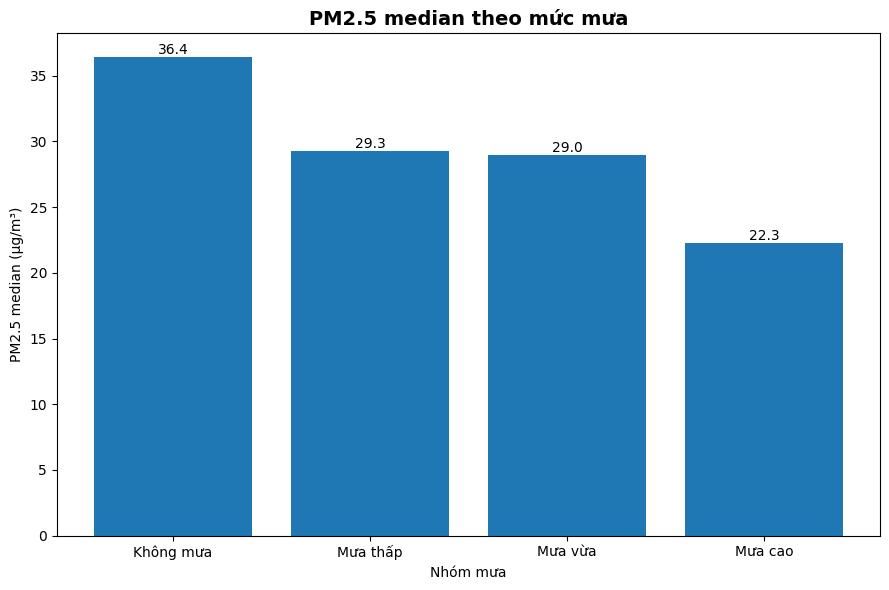

In [46]:
rain_data = ts[['Precipitation', 'PM25']].dropna().copy()

positive_rain = rain_data.loc[rain_data['Precipitation'] > 0, 'Precipitation']

if len(positive_rain) > 0:
    q1 = positive_rain.quantile(0.33)
    q2 = positive_rain.quantile(0.67)

    def rain_group(x):
        if x == 0:
            return 'Không mưa'
        elif x <= q1:
            return 'Mưa thấp'
        elif x <= q2:
            return 'Mưa vừa'
        return 'Mưa cao'

    rain_data['Rain_group'] = rain_data['Precipitation'].apply(rain_group)

    rain_summary = rain_data.groupby(
        'Rain_group'
    ).agg(
        N=('PM25', 'size'),
        Rain_median=('Precipitation', 'median'),
        PM25_median=('PM25', 'median'),
        PM25_mean=('PM25', 'mean')
    )

    order = ['Không mưa', 'Mưa thấp', 'Mưa vừa', 'Mưa cao']
    rain_summary = rain_summary.reindex([x for x in order if x in rain_summary.index])

    display(rain_summary)

    plt.figure(figsize=(9, 6))
    bars = plt.bar(rain_summary.index, rain_summary['PM25_median'])

    plt.title('PM2.5 median theo mức mưa', fontsize=14, fontweight='bold')
    plt.xlabel('Nhóm mưa')
    plt.ylabel('PM2.5 median (µg/m³)')

    for bar in bars:
        val = bar.get_height()
        plt.text(bar.get_x() + bar.get_width()/2, val, f'{val:.1f}', ha='center', va='bottom')

    plt.tight_layout()
    plt.show()

## 10.6 Hướng gió

In [47]:
wind_data = ts[['Wind Direction', 'Wind Speed', 'PM25']].dropna().copy()

direction_labels = np.array(['N', 'NE', 'E', 'SE', 'S', 'SW', 'W', 'NW'])

direction_index = (((wind_data['Wind Direction'] + 22.5) % 360) // 45).astype(int)

wind_data['Wind_sector'] = direction_labels[direction_index.values]

wind_sector_summary = wind_data.groupby('Wind_sector').agg(
    N=('PM25', 'size'),
    Wind_speed_median=('Wind Speed', 'median'),
    PM25_median=('PM25', 'median'),
    PM25_mean=('PM25', 'mean')
)

wind_order = ['N', 'NE', 'E', 'SE', 'S', 'SW', 'W', 'NW']
wind_sector_summary = wind_sector_summary.reindex(wind_order)

display(wind_sector_summary)

,N,Wind_speed_median,PM25_median,PM25_mean
Wind_sector,,,,
N,5220,1.600,35.000,47.667
NE,3167,1.660,32.400,41.495
E,5263,2.000,35.000,43.736
SE,13250,2.000,34.400,41.851
S,5068,2.000,34.000,41.694
SW,1879,1.600,32.400,41.445
W,2002,1.330,35.000,44.319
NW,4759,1.830,34.400,45.564


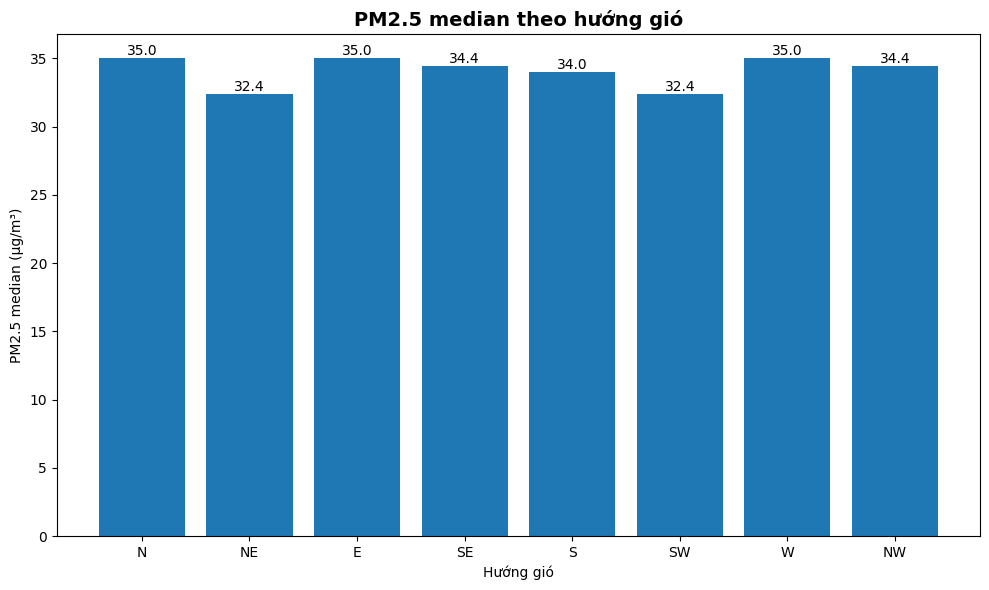

In [48]:
plt.figure(figsize=(10, 6))
bars = plt.bar(
    wind_sector_summary.index,
    wind_sector_summary['PM25_median']
)

plt.title('PM2.5 median theo hướng gió',
          fontsize=14, fontweight='bold')
plt.xlabel('Hướng gió')
plt.ylabel('PM2.5 median (µg/m³)')

for bar in bars:
    value = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width()/2,
        value,
        f'{value:.1f}',
        ha='center',
        va='bottom'
    )

plt.tight_layout()
plt.show()


## 10.7 Hướng gió × tốc độ gió

Speed_group,Gió yếu,Gió vừa,Gió mạnh
Wind_sector,,,
N,44.000,34.000,26.000
NE,40.600,32.400,25.800
E,37.400,33.400,34.000
SE,36.400,34.400,32.400
S,37.000,33.000,33.000
SW,37.200,31.100,25.800
W,38.400,35.000,25.800
NW,41.000,35.400,28.000


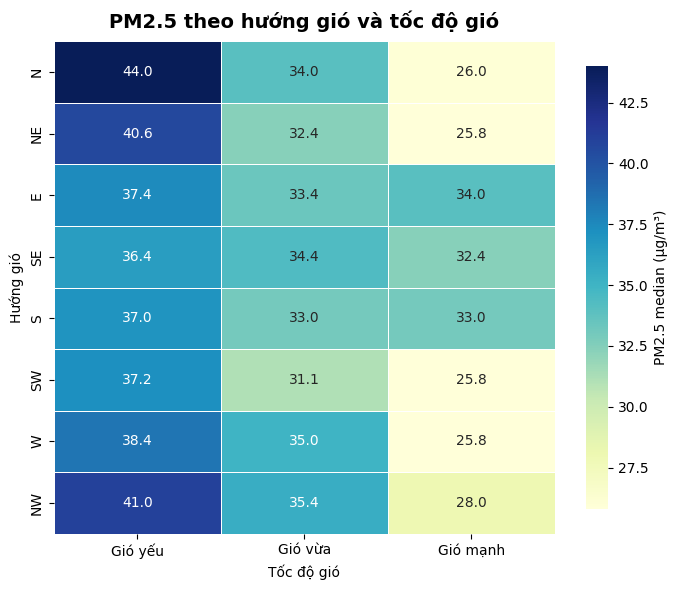

In [49]:
wind_data['Speed_group'] = pd.qcut(wind_data['Wind Speed'], q=3,
                                         labels=['Gió yếu', 'Gió vừa', 'Gió mạnh'], duplicates='drop')

wind_interaction = wind_data.pivot_table(index='Wind_sector', columns='Speed_group',
                                         values='PM25', aggfunc='median', observed=False).reindex(wind_order)

display(wind_interaction)

plt.figure(figsize=(7, 6))
ax = sns.heatmap(wind_interaction, annot=True, fmt='.1f', cmap='YlGnBu', linewidths=0.6,
                 cbar_kws={'label': 'PM2.5 median (µg/m³)', 'shrink': 0.9})

ax.set_title('PM2.5 theo hướng gió và tốc độ gió', fontsize=14, fontweight='bold', pad=10)
ax.set_xlabel('Tốc độ gió')
ax.set_ylabel('Hướng gió')

plt.tight_layout()
plt.show()


# XI. Các đợt PM2.5 cao có đặc điểm gì?

## 11.1 Kiểm tra các peak cao nhất có phải spike đơn lẻ không

In [50]:
peak_check = ts[['PM25', 'PM10', 'NO2', 'O3', 'CO', 'SO2']].copy()

peak_check['PM25_prev1h'] = peak_check['PM25'].shift(1)
peak_check['PM25_next1h'] = peak_check['PM25'].shift(-1)

peak_check['Neighbor_median'] = peak_check[['PM25_prev1h', 'PM25_next1h']].median(axis=1)

peak_check['Peak_to_neighbor'] = (peak_check['PM25'] / peak_check['Neighbor_median'])

top_peaks = (peak_check .sort_values('PM25', ascending=False) .head(20))

display(top_peaks)

,PM25,PM10,NO2,O3,CO,SO2,PM25_prev1h,PM25_next1h,Neighbor_median,Peak_to_neighbor
Local Time,,,,,,,,,,
2024-02-07 19:00:00,400.000,400.000,46.000,8.600,403.000,74.000,24.300,48.600,36.450,10.974
2025-03-20 23:00:00,390.900,452.600,24.000,2.700,10.000,4.000,380.900,118.000,249.450,1.567
2025-03-20 22:00:00,380.900,441.700,23.000,4.300,10.000,20.000,269.900,390.900,330.400,1.153
2023-12-14 03:00:00,355.500,368.000,62.000,13.000,202.000,58.000,47.300,136.400,91.850,3.870
2022-04-08 04:00:00,349.600,485.300,65.000,12.000,1663.800,97.000,332.400,329.400,330.900,1.057
2022-04-08 03:00:00,332.400,487.500,64.700,17.300,1522.200,107.300,314.200,349.600,331.900,1.002
2025-01-02 23:00:00,331.800,342.300,15.000,2.200,1210.000,32.000,322.600,258.300,290.450,1.142
2022-04-08 05:00:00,329.400,483.200,53.700,16.700,1677.300,81.000,349.600,309.200,329.400,1.000
2025-01-02 22:00:00,322.600,332.800,15.000,1.100,2117.000,32.000,300.700,331.800,316.250,1.020


## 11.2 Xác định episode PM2.5 cao

In [51]:
# P90 chỉ dùng làm ngưỡng exploratory
high_threshold = ts['PM25'].quantile(0.90)

episode_data = ts[['PM25']].copy()
episode_data['High'] = episode_data['PM25'] > high_threshold

episode_data['Group'] = (episode_data['High'] != episode_data['High'].shift(1)).cumsum()

episodes = []

for _, part in episode_data[episode_data['High']].groupby('Group'):
    episodes.append({
        'Start': part.index.min(),
        'End': part.index.max(),
        'Duration_h': len(part),
        'Mean_PM25': part['PM25'].mean(),
        'Peak_PM25': part['PM25'].max(),
        'Peak_time': part['PM25'].idxmax()
    })

episodes = pd.DataFrame(episodes)

print('Ngưỡng P90:', round(high_threshold, 2))
print('Số episode:', len(episodes))

if len(episodes) > 0:
    print('Median thời lượng:', episodes['Duration_h'].median(), 'giờ')
    print('Episode dài nhất:', episodes['Duration_h'].max(), 'giờ')
    print('Peak lớn nhất:', round(episodes['Peak_PM25'].max(), 2))
    display(episodes .sort_values('Peak_PM25', ascending=False) .head(10))

Ngưỡng P90: 83.8
Số episode: 913
Median thời lượng: 2.0 giờ
Episode dài nhất: 41 giờ
Peak lớn nhất: 400.0


,Start,End,Duration_h,Mean_PM25,Peak_PM25,Peak_time
344,2024-02-07 19:00:00,2024-02-07 19:00:00,1,400.000,400.000,2024-02-07 19:00:00
655,2025-03-20 20:00:00,2025-03-21 21:00:00,26,144.712,390.900,2025-03-20 23:00:00
275,2023-12-14 03:00:00,2023-12-14 07:00:00,5,162.400,355.500,2023-12-14 03:00:00
34,2022-04-07 17:00:00,2022-04-08 09:00:00,17,245.994,349.600,2022-04-08 04:00:00
588,2025-01-02 17:00:00,2025-01-03 14:00:00,22,195.105,331.800,2025-01-02 23:00:00
774,2025-12-12 00:00:00,2025-12-13 10:00:00,35,170.583,290.200,2025-12-13 06:00:00
342,2024-01-31 21:00:00,2024-02-02 03:00:00,31,167.216,286.200,2024-02-01 23:00:00
228,2023-11-19 18:00:00,2023-11-20 09:00:00,16,201.875,270.100,2023-11-19 20:00:00
251,2023-11-28 20:00:00,2023-11-29 18:00:00,23,159.370,264.100,2023-11-29 03:00:00
351,2024-03-04 20:00:00,2024-03-05 14:00:00,19,149.432,263.000,2024-03-04 22:00:00


## 11.3 Episode theo mùa

,So_episode,Median_duration,Mean_duration,Max_duration,Median_peak
Season,,,,,
Xuân,223,1.000,3.740,26,103.000
Hạ,67,1.000,1.701,7,110.000
Thu,222,2.500,4.131,23,109.200
Đông,401,3.000,5.446,41,111.300


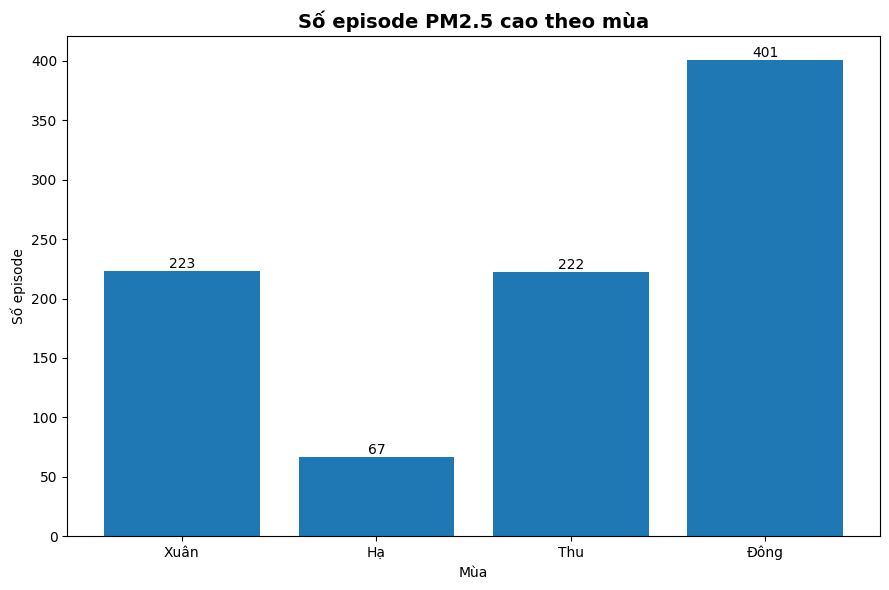

In [52]:
if len(episodes) > 0:
    episodes['Month'] = episodes['Start'].dt.month
    episodes['Season'] = episodes['Month'].apply(get_season)

    episode_season = episodes.groupby('Season').agg(
        So_episode=('Duration_h', 'size'),
        Median_duration=('Duration_h', 'median'),
        Mean_duration=('Duration_h', 'mean'),
        Max_duration=('Duration_h', 'max'),
        Median_peak=('Peak_PM25', 'median')
    ).reindex(['Xuân', 'Hạ', 'Thu', 'Đông'])

    display(episode_season)

    plt.figure(figsize=(9, 6))
    bars = plt.bar(episode_season.index, episode_season['So_episode'])

    plt.title('Số episode PM2.5 cao theo mùa', fontsize=14, fontweight='bold')
    plt.xlabel('Mùa')
    plt.ylabel('Số episode')

    for bar in bars:
        val = bar.get_height()
        plt.text(bar.get_x() + bar.get_width()/2, val, f'{int(val)}', ha='center', va='bottom')

    plt.tight_layout()
    plt.show()

## 11.4 Profile PM2.5 quanh peak episode

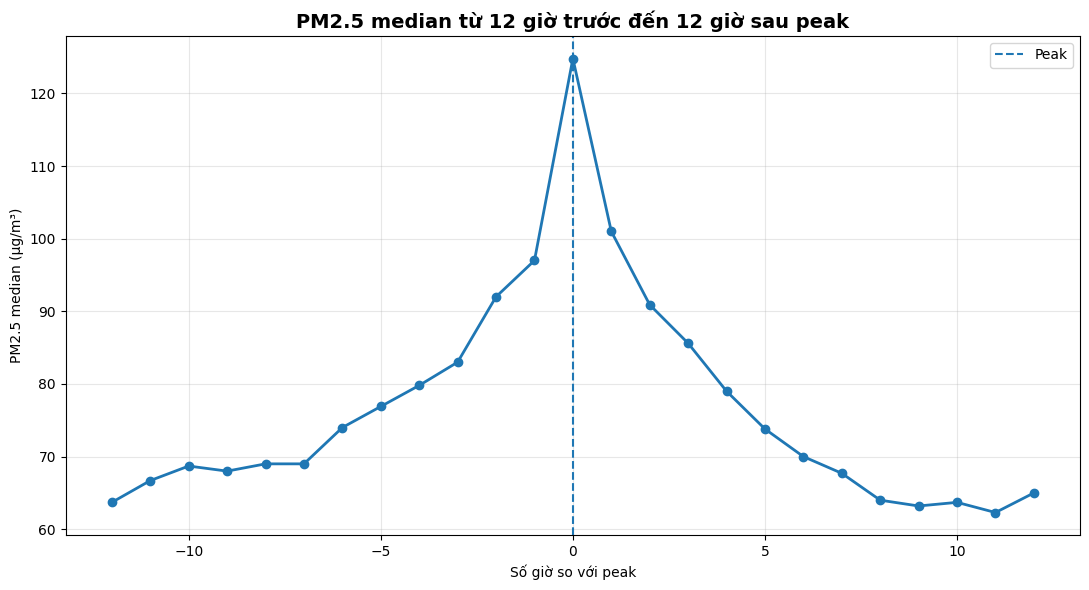

In [53]:
# Chỉ lấy các episode dài ít nhất 2 giờ để tránh quá nhiều spike một giờ
selected_peaks = []

if len(episodes) > 0:
    selected_peaks = (episodes.loc[episodes['Duration_h'] >= 2, 'Peak_time'] .dropna() .tolist())

profiles = []

for peak_time in selected_peaks:
    start = peak_time - pd.Timedelta(hours=12)
    end = peak_time + pd.Timedelta(hours=12)

    part = ts.loc[start:end, ['PM25']].copy()

    if len(part) == 25:
        part['Relative_hour'] = range(-12, 13)
        profiles.append(part[['Relative_hour', 'PM25']])

if len(profiles) > 0:
    profile_df = pd.concat(profiles)

    profile_summary = profile_df.groupby('Relative_hour')['PM25'].median()

    plt.figure(figsize=(11, 6))
    plt.plot(profile_summary.index, profile_summary.values, marker='o', linewidth=2)

    plt.axvline(0, linestyle='--', label='Peak')
    plt.title('PM2.5 median từ 12 giờ trước đến 12 giờ sau peak', fontsize=14, fontweight='bold')
    plt.xlabel('Số giờ so với peak')
    plt.ylabel('PM2.5 median (µg/m³)')
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()
else:
    print('Không đủ episode để tạo profile.')

# XII. Dữ liệu có distribution drift theo năm không?

In [54]:
year_stats = eda_time.groupby('Year')['PM25'].agg(
    count='count',
    mean='mean',
    median='median',
    std='std',
    q25=lambda x: x.quantile(0.25),
    q75=lambda x: x.quantile(0.75),
    p90=lambda x: x.quantile(0.90),
    p95=lambda x: x.quantile(0.95)
)

display(year_stats)


,count,mean,median,std,q25,q75,p90,p95
Year,,,,,,,,
2022,8472,40.099,31.300,31.023,21.200,48.500,75.800,101.000
2023,8760,43.703,34.400,33.755,22.600,52.600,81.600,118.200
2024,8784,45.400,36.400,35.683,21.200,55.600,92.000,123.400
2025,8760,45.909,36.000,33.817,25.000,57.000,90.000,114.000
2026,5832,40.497,35.000,24.863,25.000,47.050,71.000,91.360


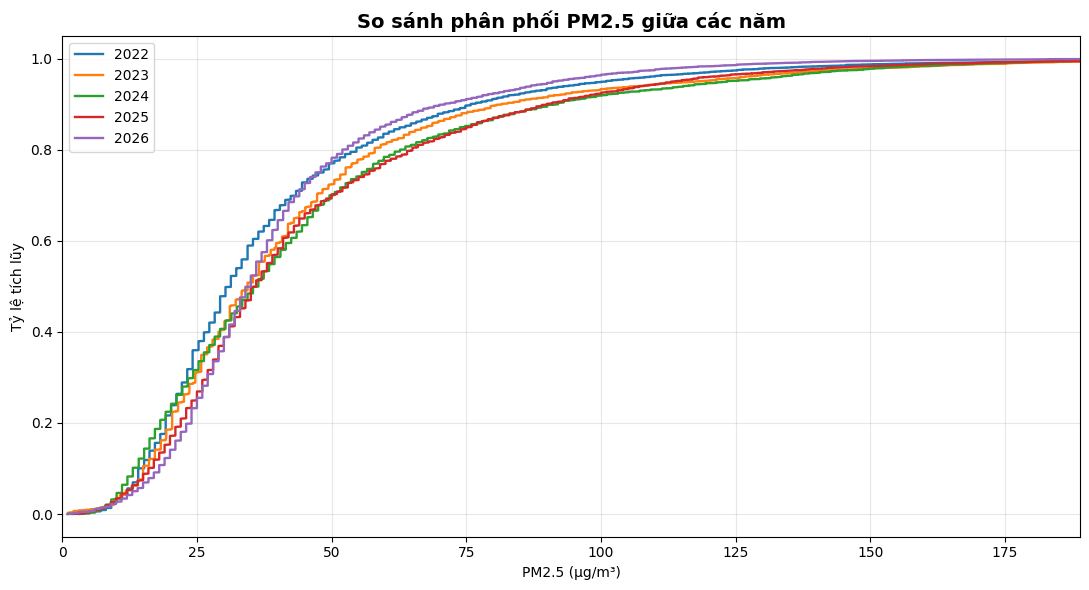

In [55]:
years = sorted(eda_time['Year'].dropna().unique())

plt.figure(figsize=(11, 6))

for year in years:
    part = eda_time.loc[
        eda_time['Year'] == year,
        'PM25'
    ].dropna()

    # ECDF theo năm
    x = np.sort(part.values)
    y = np.arange(1, len(x) + 1) / len(x)

    plt.plot(x, y, label=str(year), linewidth=1.7)

plt.title('So sánh phân phối PM2.5 giữa các năm',
          fontsize=14, fontweight='bold')
plt.xlabel('PM2.5 (µg/m³)')
plt.ylabel('Tỷ lệ tích lũy')
plt.legend()
plt.grid(alpha=0.3)
plt.xlim(0, pm25.quantile(0.995))
plt.tight_layout()
plt.show()


In [56]:
from scipy.stats import mannwhitneyu

jan_aug = eda_time[eda_time['Month'].between(1, 8)].copy()

pm25_2026 = jan_aug.loc[jan_aug['Year'] == 2026, 'PM25'].dropna()

pm25_old = jan_aug.loc[jan_aug['Year'].between(2022, 2025), 'PM25'].dropna()

stat, p_value = mannwhitneyu(pm25_2026, pm25_old, alternative='two-sided')

print('So sánh Jan-Aug 2026 với Jan-Aug 2022-2025')
print('Median 2026:', round(pm25_2026.median(), 2))
print('Median 2022-2025:', round(pm25_old.median(), 2))
print('Chênh median:', round(pm25_2026.median() - pm25_old.median(), 2))
print('p-value:', p_value)

So sánh Jan-Aug 2026 với Jan-Aug 2022-2025
Median 2026: 35.0
Median 2022-2025: 32.2
Chênh median: 2.8
p-value: 1.0827342484882169e-15


In [57]:
from scipy.stats import kruskal

year_groups = [eda_time.loc[eda_time['Year'] == y, 'PM25'].dropna().values
               for y in sorted(eda_time['Year'].dropna().unique())]

stat, p_kw = kruskal(*year_groups)

print('Kruskal-Wallis toàn bộ các năm')
print('H =', round(stat, 2), '| p =', p_kw)

Kruskal-Wallis toàn bộ các năm
H = 212.37 | p = 8.205447649567832e-45


# XIII. Yếu tố ngoài khí tượng

In [58]:
EXTERNAL_COLS = ['Soil Moisture', 'Boundary Layer Height', 'Dew Point', 'Wind Speed 10m',
                 'Fire Count 100km 3d', 'Fire FRP 100km 7d', 'Fire Dist Min']
v2 = ts
new_cols = [c for c in EXTERNAL_COLS if c in v2.columns]
print('Các cột dữ liệu ngoài:')
print(new_cols)

Các cột dữ liệu ngoài:
['Soil Moisture', 'Boundary Layer Height', 'Dew Point', 'Wind Speed 10m', 'Fire Count 100km 3d', 'Fire FRP 100km 7d', 'Fire Dist Min']


## 13.1 Tương quan có còn giữ sau khi loại mùa vụ không

In [59]:
from scipy.stats import pearsonr, spearmanr

new_rows = []

for col in new_cols:
    pair = v2[['PM25', col]].dropna()

    if len(pair) < 1000:
        continue

    r_all, _ = pearsonr(pair['PM25'], pair[col])
    rho_all, _ = spearmanr(pair['PM25'], pair[col])

    month = pair.index.month
    anom = pair - pair.groupby(month).transform('median')
    r_anom, p_anom = pearsonr(anom['PM25'], anom[col])
    rho_anom, _ = spearmanr(anom['PM25'], anom[col])

    new_rows.append({
        'Biến': col,
        'r gốc': r_all,
        'r sau trừ mùa': r_anom,
        'p sau trừ mùa': p_anom,
        'rho gốc': rho_all,
        'rho sau trừ mùa': rho_anom,
        'Số giờ': len(pair),
        'Thiếu (%)': v2[col].isna().mean() * 100
    })

new_corr = pd.DataFrame(new_rows).sort_values('r gốc', key=abs, ascending=False)
display(new_corr.round(3).reset_index(drop=True))

,Biến,r gốc,r sau trừ mùa,p sau trừ mùa,rho gốc,rho sau trừ mùa,Số giờ,Thiếu (%)
0,Soil Moisture,-0.435,-0.249,0.000,-0.481,-0.302,40608,0.000
1,Dew Point,-0.371,-0.070,0.000,-0.419,-0.056,40608,0.000
2,Fire Count 100km 3d,0.332,0.254,0.000,0.238,0.199,40584,0.059
3,Fire FRP 100km 7d,0.265,0.173,0.000,0.269,0.164,40584,0.059
4,Wind Speed 10m,-0.176,-0.241,0.000,-0.172,-0.281,40608,0.000
5,Boundary Layer Height,-0.170,-0.213,0.000,-0.201,-0.282,36240,10.757
6,Fire Dist Min,-0.091,-0.124,0.000,-0.104,-0.153,40584,0.059


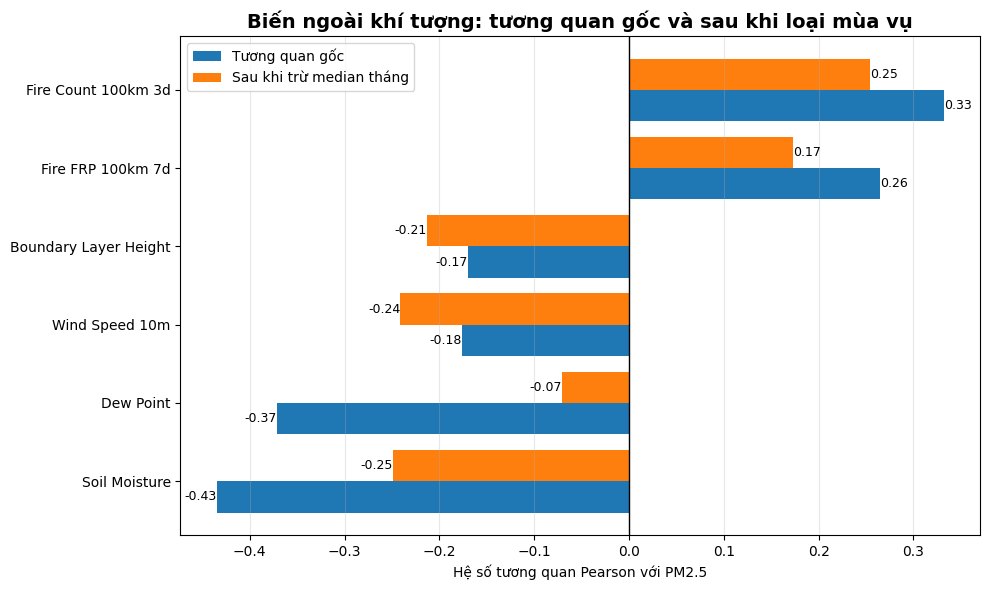

In [60]:
plot_cols = [c for c in ['Soil Moisture', 'Boundary Layer Height', 'Wind Speed 10m',
                       'Fire Count 100km 3d', 'Fire FRP 100km 7d', 'Dew Point']
             if c in new_corr['Biến'].values]

plot_df = new_corr.set_index('Biến').loc[plot_cols].sort_values('r gốc')

y = np.arange(len(plot_df))

fig, ax = plt.subplots(figsize=(10, 6))

ax.barh(y - 0.2, plot_df['r gốc'], height=0.4, label='Tương quan gốc')
ax.barh(y + 0.2, plot_df['r sau trừ mùa'], height=0.4, label='Sau khi trừ median tháng')

for k, (val_goc, val_sau) in enumerate(zip(plot_df['r gốc'], plot_df['r sau trừ mùa'])):
    ax.text(val_goc, k - 0.2, f'{val_goc:.2f}', va='center',
            ha='left' if val_goc >= 0 else 'right', fontsize=9)
    ax.text(val_sau, k + 0.2, f'{val_sau:.2f}', va='center',
            ha='left' if val_sau >= 0 else 'right', fontsize=9)

ax.set_yticks(y)
ax.set_yticklabels(plot_df.index)
ax.axvline(0, color='black', linewidth=1)
ax.set_xlabel('Hệ số tương quan Pearson với PM2.5')
ax.set_title('Biến ngoài khí tượng: tương quan gốc và sau khi loại mùa vụ',
             fontsize=14, fontweight='bold')
ax.legend()
ax.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

,Soil_median,PM25_median,N
Group,,,
"(0.055, 0.24]",0.193,54.000,8135
"(0.24, 0.304]",0.277,39.400,8151
"(0.304, 0.352]",0.329,34.000,8238
"(0.352, 0.395]",0.374,30.000,8046
"(0.395, 0.442]",0.417,22.300,8038


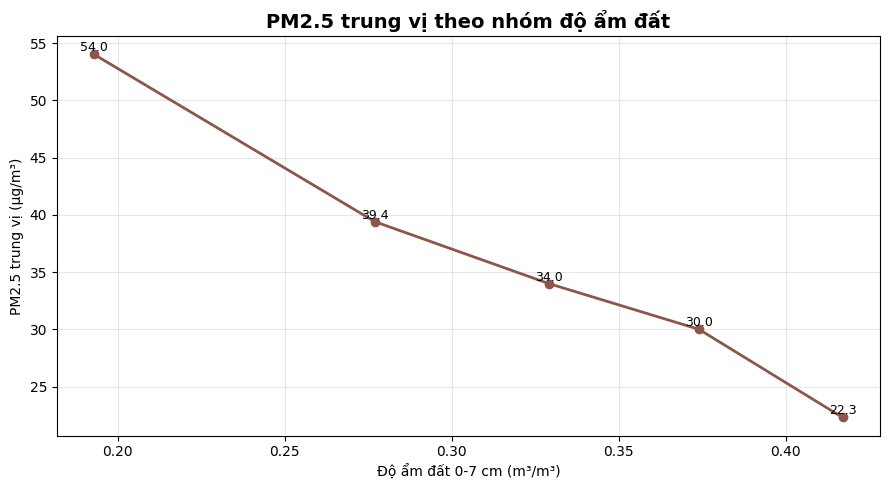

In [61]:
soil = v2[['Soil Moisture', 'PM25']].dropna().copy()
soil['Group'] = pd.qcut(soil['Soil Moisture'], q=5, duplicates='drop')

soil_summary = soil.groupby('Group', observed=False).agg(
    Soil_median=('Soil Moisture', 'median'),
    PM25_median=('PM25', 'median'),
    N=('PM25', 'size')
)
display(soil_summary)

fig, ax = plt.subplots(figsize=(9, 5))

ax.plot(soil_summary['Soil_median'], soil_summary['PM25_median'],
        marker='o', linewidth=2, color='tab:brown')

for x, val in zip(soil_summary['Soil_median'], soil_summary['PM25_median']):
    ax.text(x, val, f'{val:.1f}', ha='center', va='bottom', fontsize=9)

ax.set_title('PM2.5 trung vị theo nhóm độ ẩm đất', fontsize=14, fontweight='bold')
ax.set_xlabel('Độ ẩm đất 0-7 cm (m³/m³)')
ax.set_ylabel('PM2.5 trung vị (µg/m³)')
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 13.2 Kiểm tra đa cộng tuyến với biến đã có

In [62]:
pairs = [
    ('Wind Speed', 'Wind Speed 10m'),
    ('Temperature', 'Dew Point'),
    ('Pressure', 'Dew Point'),
    ('Temperature', 'Soil Moisture'),
]

rows = []

for a, b in pairs:
    pair = v2[[a, b]].dropna()
    r = pair[a].corr(pair[b])
    rows.append({
        'Cặp biến': f'{a} ~ {b}',
        'r': r,
        'Kết luận': 'trùng lặp cao, cân nhắc bỏ' if abs(r) > 0.85 else 'giữ được'
    })

trung_lap = pd.DataFrame(rows)
display(trung_lap.round(3))

cao = trung_lap[trung_lap['r'].abs() > 0.85]

if len(cao) > 0:
    print('Các cặp trùng lặp cần xem lại:')
    print(cao['Cặp biến'].tolist())
else:
    print('Không có cặp nào trùng lặp nghiêm trọng')

,Cặp biến,r,Kết luận
0,Wind Speed ~ Wind Speed 10m,0.468,giữ được
1,Temperature ~ Dew Point,0.859,"trùng lặp cao, cân nhắc bỏ"
2,Pressure ~ Dew Point,-0.873,"trùng lặp cao, cân nhắc bỏ"
3,Temperature ~ Soil Moisture,0.234,giữ được


Các cặp trùng lặp cần xem lại:
['Temperature ~ Dew Point', 'Pressure ~ Dew Point']


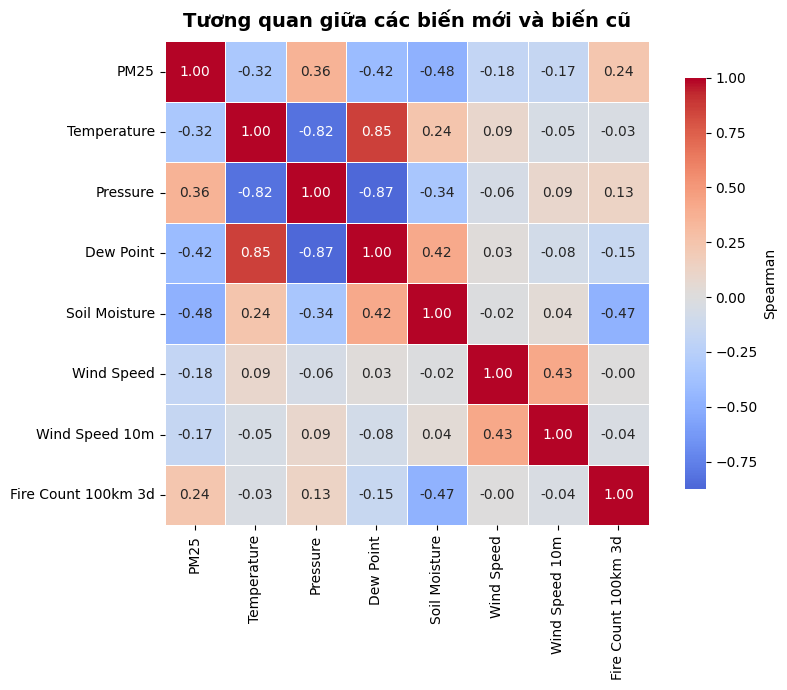

In [63]:
check_matrix = v2[['PM25', 'Temperature', 'Pressure', 'Dew Point',
                     'Soil Moisture', 'Wind Speed', 'Wind Speed 10m',
                     'Fire Count 100km 3d']].dropna()

plt.figure(figsize=(9, 7))

sns.heatmap(check_matrix.corr(method='spearman'),
            annot=True, fmt='.2f', cmap='coolwarm', center=0,
            square=True, linewidths=0.6,
            cbar_kws={'label': 'Spearman', 'shrink': 0.85})

plt.title('Tương quan giữa các biến mới và biến cũ', fontsize=14, fontweight='bold', pad=10)
plt.tight_layout()
plt.show()

## 13.3 Cột cháy có độ phân giải thời gian thấp

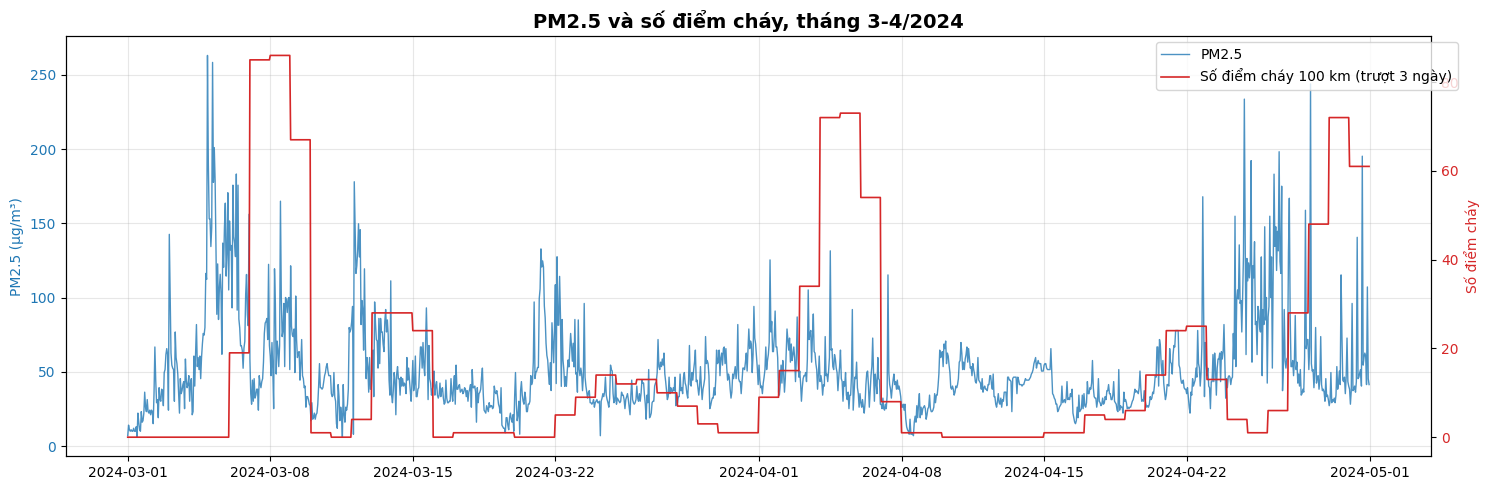

In [64]:
fire_view = v2.loc['2024-03-01':'2024-04-30', ['Fire Count 100km 3d', 'PM25']].copy()

fig, ax1 = plt.subplots(figsize=(15, 5))

ax1.plot(fire_view['PM25'], color='tab:blue', alpha=0.8, linewidth=1, label='PM2.5')
ax1.set_ylabel('PM2.5 (µg/m³)', color='tab:blue')
ax1.tick_params(axis='y', labelcolor='tab:blue')

ax2 = ax1.twinx()
ax2.plot(fire_view['Fire Count 100km 3d'], color='tab:red', linewidth=1.2, label='Số điểm cháy 100 km (trượt 3 ngày)')
ax2.set_ylabel('Số điểm cháy', color='tab:red')
ax2.tick_params(axis='y', labelcolor='tab:red')

plt.title('PM2.5 và số điểm cháy, tháng 3-4/2024', fontsize=14, fontweight='bold')
ax1.grid(alpha=0.3)
fig.legend(loc='upper right', bbox_to_anchor=(0.98, 0.92))
plt.tight_layout()
plt.show()